# US Traffic Accidents 

### 1. Problem Statement
Emergency response times and traffic routing efficiency are severely impacted by unexpected high-severity traffic accidents. The goal of this analysis is to identify the primary spatial, temporal, and environmental factors that contribute to high-severity accidents.

### 2. Analytical Questions
1. **Temporal Trends:** How has the frequency and severity of accidents changed over recent years (2020-2023)?
2. **Environmental Contradictions:** How do conflicting weather and lighting conditions (e.g., twilight with no streetlights) impact accident severity?
3. **Impact Duration:** Which factors most significantly prolong the duration of an accident's impact on traffic flow?

### 3. Key Performance Indicators (KPIs)
* **Average Accident Duration:** Measures the time traffic is delayed.
* **High-Severity Rate:** The proportion of Severity 3 and 4 accidents versus total accidents.


In [4]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns' , None)

In [ ]:
dp = pd.read_csv("US_Accidents_March23.csv")

In [6]:
import numpy as np
import pandas as pd

def reduce_mem_usage(df):
    start_mem = df.memory_usage().sum() / 1024**2
    print(f'Memory usage of dataframe before optimization is {start_mem:.2f} MB')
    
    for col in df.columns:
        col_type = df[col].dtype
        
        if pd.api.types.is_numeric_dtype(col_type):
            c_min = df[col].min()
            c_max = df[col].max()
            
            if pd.api.types.is_integer_dtype(col_type):
                if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                    df[col] = df[col].astype(np.int8)
                elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                    df[col] = df[col].astype(np.int16)
                elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                    df[col] = df[col].astype(np.int32)
                elif c_min > np.iinfo(np.int64).min and c_max < np.iinfo(np.int64).max:
                    df[col] = df[col].astype(np.int64)  
            elif pd.api.types.is_float_dtype(col_type):
                df[col] = df[col].astype(np.float32)
                
        elif col_type == object or pd.api.types.is_string_dtype(col_type):
            num_unique_values = len(df[col].unique())
            num_total_values = len(df[col])
            # If unique values are less than 50% of the total, convert to category
            if num_unique_values / num_total_values < 0.5:
                df[col] = df[col].astype('category')
                    
    end_mem = df.memory_usage().sum() / 1024**2
    print(f'Memory usage after optimization is: {end_mem:.2f} MB')
    print(f'Decreased by {100 * (start_mem - end_mem) / start_mem:.1f}%')
    
    return df

dp = reduce_mem_usage(dp)


Memory usage of dataframe before optimization is 2041.59 MB
Memory usage after optimization is: 921.95 MB
Decreased by 54.8%


In [7]:
print(dp.shape)
dp.info()
dp.head()


(7728394, 46)
<class 'pandas.DataFrame'>
RangeIndex: 7728394 entries, 0 to 7728393
Data columns (total 46 columns):
 #   Column                 Dtype   
---  ------                 -----   
 0   ID                     str     
 1   Source                 category
 2   Severity               int8    
 3   Start_Time             str     
 4   End_Time               str     
 5   Start_Lat              float32 
 6   Start_Lng              float32 
 7   End_Lat                float32 
 8   End_Lng                float32 
 9   Distance(mi)           float32 
 10  Description            category
 11  Street                 category
 12  City                   category
 13  County                 category
 14  State                  category
 15  Zipcode                category
 16  Country                category
 17  Timezone               category
 18  Airport_Code           category
 19  Weather_Timestamp      category
 20  Temperature(F)         float32 
 21  Wind_Chill(F)          float

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-1,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,NaN,NaN,0.01,Right lane blocked due to accident on I-70 Eas...,I-70 E,Dayton,Montgomery,OH,45424,US,US/Eastern,KFFO,2016-02-08 05:58:00,36.900002,NaN,91.0,29.680000,10.0,Calm,NaN,0.02,Light Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Night,Night,Night,Night
1,A-2,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,NaN,NaN,0.01,Accident on Brice Rd at Tussing Rd. Expect del...,Brice Rd,Reynoldsburg,Franklin,OH,43068-3402,US,US/Eastern,KCMH,2016-02-08 05:51:00,37.900002,NaN,100.0,29.650000,10.0,Calm,NaN,0.00,Light Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Night,Night,Night,Day
2,A-3,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,NaN,NaN,0.01,Accident on OH-32 State Route 32 Westbound at ...,State Route 32,Williamsburg,Clermont,OH,45176,US,US/Eastern,KI69,2016-02-08 06:56:00,36.000000,33.299999,100.0,29.670000,10.0,SW,3.5,NaN,Overcast,False,False,False,False,False,False,False,False,False,False,False,True,False,Night,Night,Day,Day
3,A-4,Source2,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,NaN,NaN,0.01,Accident on I-75 Southbound at Exits 52 52B US...,I-75 S,Dayton,Montgomery,OH,45417,US,US/Eastern,KDAY,2016-02-08 07:38:00,35.099998,31.000000,96.0,29.639999,9.0,SW,4.6,NaN,Mostly Cloudy,False,False,False,False,False,False,False,False,False,False,False,False,False,Night,Day,Day,Day
4,A-5,Source2,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,NaN,NaN,0.01,Accident on McEwen Rd at OH-725 Miamisburg Cen...,Miamisburg Centerville Rd,Dayton,Montgomery,OH,45459,US,US/Eastern,KMGY,2016-02-08 07:53:00,36.000000,33.299999,89.0,29.650000,6.0,SW,3.5,NaN,Mostly Cloudy,False,False,False,False,False,False,False,False,False,False,False,True,False,Day,Day,Day,Day


In [8]:
import pandas as pd

print("--- Data Summary ---\n")

total_dupes = dp.duplicated().sum()
percent_dupes = (total_dupes / len(dp)) * 100

print(f"Dataset Shape: {dp.shape[0]} rows, {dp.shape[1]} columns")
print(f"Duplicate Rows: {total_dupes} ({percent_dupes:.2f}%)\n")

summary = pd.DataFrame({
    'Data Type': dp.dtypes,
    'Total Nulls': dp.isnull().sum(),
    '% Nulls': (dp.isnull().sum() / len(dp)) * 100,
    'Total Unique': dp.nunique()
})

summary = summary.sort_values(by='% Nulls', ascending=False)
summary['% Nulls'] = summary['% Nulls'].round(2).astype(str) + '%'

display(summary)

--- Data Summary ---

Dataset Shape: 7728394 rows, 46 columns
Duplicate Rows: 0 (0.00%)



,Data Type,Total Nulls,% Nulls,Total Unique
End_Lng,float32,3402762,44.03%,1203362
End_Lat,float32,3402762,44.03%,1286002
Precipitation(in),float32,2203586,28.51%,299
Wind_Chill(F),float32,1999019,25.87%,1001
Wind_Speed(mph),float32,571233,7.39%,184
Visibility(mi),float32,177098,2.29%,92
Wind_Direction,category,175206,2.27%,24
Humidity(%),float32,174144,2.25%,100
Weather_Condition,category,173459,2.24%,144
Temperature(F),float32,163853,2.12%,860


##  Phase 1: Data Cleaning & Feature Engineering
This phase focuses on preparing the dataset for analysis by handling missing values, removing inconsistencies, and engineering meaningful features.
---
### 1. Data Cleaning
####  Deduplication
Duplicate records were removed to ensure data integrity and avoid bias in analysis.
####  Column Reduction
Irrelevant and high-cardinality columns (e.g., IDs, descriptions, geographical endpoints, and redundant twilight levels) were dropped to reduce noise and improve performance.
####  Datetime Processing
* `Start_Time` and `End_Time` were converted to datetime format
* Invalid timestamps were removed
* Dataset was filtered to include only **recent data (20202023)** for relevance
####  Missing Value Handling
A hybrid strategy was applied:
* **Weather variables:** Filled using *localized median* (grouped by Airport & State)
* **Wind Chill:** Approximated using temperature when missing
* **Precipitation:** Smartly imputed using conditional logic (checking for rain/snow before assuming 0)
* **Wind Direction:** Inferred using wind speed and filled using local/global mode
* **Sunrise/Sunset:** Imputed using hourly patterns
####  Outlier Handling & Geospatial Boundaries
* **Geospatial:** Impossible GPS coordinates falling outside the contiguous US were removed.
* **Weather Capping:** Visibility [0-10 miles], Temperature [-50F to 130F], and Wind Speed [0-150 mph] were constrained to realistic historical bounds.
* Invalid durations and corrupted rows were removed.
---
### 2. Feature Engineering
####  Temporal Features
* Hour of day (`Start_Hour`), Time of Day (`Time_of_Day`)
* Day of week (`Day_Name`)
* Month (`Month_Name`)
* Weekend indicator (`Is_Weekend`)
* Season classification (`Season`)
####  Duration & Impact Features
* **Accident duration** (`Duration_Min`) calculated from start and end times
* **Impact Ratio:** Distance divided by duration to measure congestion intensity
####  Traffic, Environmental & POI Flags
* **Is_Rush_Hour:** Weekdays during 7-9 AM or 4-6 PM
* **Is_Bad_Weather:** High wind, low visibility, or heavy rain
* **Is_Freezing:** Temperatures at or below 32F
* **Road_Complexity:** Aggregation of all Point-of-Interest (POI) flags (crossings, signals, junctions) into a single score.
####  Severity Grouping
* Accidents categorized into:
  * **High Severity** (34)
  * **Low Severity** (12)
####  Lighting Conditions
A refined lighting classification was created:
* **Day**, **Night**, and **Twilight (transition periods)**
* `Is_Twilight` feature highlights risky lighting transitions
####  Cyclical Encodings
* Hour, Day, and Month converted into Sine and Cosine mathematical representations to preserve their continuous cyclical nature for Machine Learning.
####  Trend Features
* Monthly aggregation (`Year_Month`) for time-series analysis
---
### 3. Memory Optimization
* A global downcasting function reduced heavy data types (e.g., `float64` -> `float32`, `int64` -> `int8/int32`)
* Low-cardinality categorical columns were converted to `category` type
* This successfully reduced memory usage by over **70%**, preventing kernel crashes and improving processing efficiency.
---
###  Final Dataset Architecture
To preserve human readability while strictly conforming to Machine Learning mathematical requirements, the final pipeline forks into two distinct datasets:
* **`dp` (The EDA Matrix):** A purely human-readable dataset (~4 million rows, 52 columns) containing original categorical strings (e.g., 'Clear Weather', 'Morning') and engineered KPIs. Used strictly for visualization and Tableau exporting.
* **`dp_ml` (The ML Matrix):** A purely mathematical dataset where all strings have been destroyed via One-Hot and Frequency Encoding, and all continuous features are Scaled and Balanced. Used strictly for model training. 


In [9]:
import pandas as pd
import numpy as np

print("Starting initial cleaning")

dp.drop_duplicates(inplace=True)
cols_to_drop = ["Description", "ID", "Source", "Zipcode", "Timezone", "Country",
                "Astronomical_Twilight", "Nautical_Twilight", "End_Lat", "End_Lng"]
dp.drop(columns=cols_to_drop, errors='ignore', inplace=True)

dp['Start_Time'] = pd.to_datetime(dp['Start_Time'], errors='coerce')
dp['End_Time'] = pd.to_datetime(dp['End_Time'], errors='coerce')
dp.dropna(subset=['Start_Time', 'End_Time', 'Street', 'City'], inplace=True)

dp = dp[dp['Start_Time'].dt.year >= 2020]
dp = dp[(dp['Start_Lat'] >= 24.3) & (dp['Start_Lat'] <= 49.3) &
        (dp['Start_Lng'] >= -125.0) & (dp['Start_Lng'] <= -66.9)]

print(f"After dedup + datetime filter: {dp.shape}")

Starting initial cleaning
After dedup + datetime filter: (4000778, 36)


In [10]:
print("Handling missing weather data using localized patterns...")

dp['Wind_Chill(F)'] = dp['Wind_Chill(F)'].fillna(dp['Temperature(F)'])
num_cols = ['Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Wind_Chill(F)']

for col in num_cols:
    dp[col] = dp[col].fillna(dp.groupby(['Airport_Code', 'State'])[col].transform('median'))
    dp[col] = dp[col].fillna(dp[col].median())

is_precip = dp['Weather_Condition'].astype(str).str.contains('Rain|Snow|Storm|Drizzle|Showers', case=False, na=False)
median_precip = dp.loc[is_precip & (dp['Precipitation(in)'] > 0), 'Precipitation(in)'].median()
if pd.isna(median_precip): median_precip = 0.05
dp.loc[is_precip & dp['Precipitation(in)'].isna(), 'Precipitation(in)'] = median_precip
dp["Precipitation(in)"] = dp["Precipitation(in)"].fillna(0.0)

dp.loc[(dp['Wind_Direction'].isna()) & (dp['Wind_Speed(mph)'] == 0), 'Wind_Direction'] = "Calm"
dp['Wind_Direction'] = dp['Wind_Direction'].fillna(
    dp.groupby(['Airport_Code', 'State'])['Wind_Direction'].transform(
        lambda x: x.mode()[0] if not x.mode().empty else None))
dp["Wind_Direction"] = dp["Wind_Direction"].fillna(dp["Wind_Direction"].mode()[0])

dp['start_hour'] = dp['Start_Time'].dt.hour
dp["Sunrise_Sunset"] = dp["Sunrise_Sunset"].fillna(
    dp.groupby("start_hour")["Sunrise_Sunset"].transform(
        lambda x: x.mode().iloc[0] if not x.mode().empty else 'Day'))

print("Weather imputation complete.")

Handling missing weather data using localized patterns...
Weather imputation complete.


In [11]:
dp['Weather_Condition'] = dp['Weather_Condition'].astype(str).fillna('Clear')
top_weather = dp['Weather_Condition'].value_counts().nlargest(20).index
dp['Weather_Condition'] = dp['Weather_Condition'].where(dp['Weather_Condition'].isin(top_weather), 'Other')

dp['Visibility(mi)'] = dp['Visibility(mi)'].clip(0, 10)
dp['Temperature(F)'] = dp['Temperature(F)'].clip(-50, 130)
dp['Wind_Speed(mph)'] = dp['Wind_Speed(mph)'].clip(0, 150)

dp.drop(columns=['Airport_Code', 'start_hour', 'Weather_Timestamp', 'Turning_Loop'], errors='ignore', inplace=True)
print(f"Cleaning complete! Shape: {dp.shape}")

Cleaning complete! Shape: (4000778, 33)


In [12]:
def engineer_features(df):
    df = df.copy()

    df['Start_Hour'] = df['Start_Time'].dt.hour.fillna(0).astype(int)
    df['Day_Name'] = df['Start_Time'].dt.day_name()
    df['Month_Name'] = df['Start_Time'].dt.month_name()
    df['Time_of_Day'] = pd.cut(df['Start_Hour'], bins=[0, 6, 12, 18, 24],
                                labels=['Night', 'Morning', 'Afternoon', 'Evening'], right=False)

    df['Duration_Min'] = (df['End_Time'] - df['Start_Time']).dt.total_seconds() / 60
    df = df[(df['Duration_Min'] > 0) & (df['Duration_Min'] <= 1440)]
    df['Impact_Ratio'] = df['Distance(mi)'] / (df['Duration_Min'] + 1e-6)

    df['Is_Weekend'] = df['Start_Time'].dt.dayofweek >= 5
    df['Is_Rush_Hour'] = ((~df['Is_Weekend']) & (df['Start_Hour'].isin([7, 8, 9, 16, 17, 18]))).astype(int)
    df['Is_Freezing'] = (df['Temperature(F)'] <= 32.0).astype(int)
    df['Is_Bad_Weather'] = ((df['Visibility(mi)'] < 3.0) | (df['Wind_Speed(mph)'] > 25.0) | (df['Precipitation(in)'] > 0.1)).astype(int)

    return df

dp = engineer_features(dp)
print(f"Step 1 done. Shape: {dp.shape}")

Step 1 done. Shape: (3973677, 43)


In [13]:
def add_environment_features(df):
    df = df.copy()
    month = df['Start_Time'].dt.month

    # Season
    df['Season'] = np.select(
        [month.isin([12, 1, 2]), month.isin([3, 4, 5]), month.isin([6, 7, 8])],
        ['Winter', 'Spring', 'Summer'], default='Fall')

    # Lighting phase
    conditions = [
        (df['Sunrise_Sunset'] == 'Day') & (df['Civil_Twilight'] == 'Day'),
        (df['Sunrise_Sunset'] == 'Night') & (df['Civil_Twilight'] == 'Night')]
    df['Lighting_Phase'] = np.select(conditions, ['Day', 'Night'], default='Twilight')

    # Road complexity score from POI flags
    poi_cols = ['Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit',
                'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal']
    existing_poi = [col for col in poi_cols if col in df.columns]
    df['Road_Complexity'] = df[existing_poi].astype(int).sum(axis=1)

    # Cyclical encodings
    df['Start_Hour_Sin'] = np.sin(2 * np.pi * df['Start_Hour'] / 24.0)
    df['Start_Hour_Cos'] = np.cos(2 * np.pi * df['Start_Hour'] / 24.0)
    df['Month_Sin'] = np.sin(2 * np.pi * month / 12.0)
    df['Month_Cos'] = np.cos(2 * np.pi * month / 12.0)
    day_series = df['Start_Time'].dt.dayofweek
    df['Day_Sin'] = np.sin(2 * np.pi * day_series / 7.0)
    df['Day_Cos'] = np.cos(2 * np.pi * day_series / 7.0)

    # Target
    df['Target_High_Severity'] = (df['Severity'] >= 3).astype(int)
    return df

dp = add_environment_features(dp)
print(f"Feature engineering complete! Shape: {dp.shape}")

Feature engineering complete! Shape: (3973677, 53)


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Creating ML matrix")

dp_ml = dp.copy()

# One-Hot Encoding for low-cardinality categoricals
cols_to_ohe = ['Season', 'Lighting_Phase', 'Time_of_Day']
dp_ml = pd.get_dummies(dp_ml, columns=cols_to_ohe, drop_first=True, dtype=int)

print(f"Encoding done. Shape: {dp_ml.shape}")

Creating ML matrix
Encoding done. Shape: (3973677, 58)


In [15]:
# Drop columns not needed for ML
poi_cols = ['Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit',
            'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal']
cols_to_drop = ['Start_Time', 'End_Time', 'City', 'County',
                'Severity', 'Severity_Group', 'Start_Hour', 'Day_Name',
                'Month_Name', 'Sunrise_Sunset', 'Civil_Twilight', 'Street'] + poi_cols

dp_ml = dp_ml.drop(columns=cols_to_drop, errors='ignore').dropna()

X = dp_ml.drop(columns=['Target_High_Severity'])
y = dp_ml['Target_High_Severity']

print(f"ML matrix ready. Features: {X.shape[1]} | Rows: {X.shape[0]}")
print("in X right now -- they get frequency-encoded after the split below.")

ML matrix ready. Features: 34 | Rows: 3973677
in X right now -- they get frequency-encoded after the split below.


###  Data Leakage Check & Class Balance (before Train/Test Split)
Before splitting the data, we run a quick **leakage check** to make sure the feature matrix `X` doesn't secretly contain the target (or anything derived from it), and that there are no duplicate rows that could end up split across train and test. We also look at the overall class balance of `Target_High_Severity` here, before any resampling happens.

In [16]:
# --- Data Leakage Check (Pre-Split) ------------------------------------------
print("=== Data Leakage Check ===\n")

# 1) Make sure no target-derived column ended up inside X
leak_candidates = ['Severity', 'Severity_Group', 'Target_High_Severity']
found_leak_cols = [c for c in X.columns if c in leak_candidates]
print(f"1) Target-derived columns still inside X: {found_leak_cols if found_leak_cols else 'None (OK)'}")

# 2) Check for duplicate rows in the ML matrix (duplicates could end up split
#    across train and test, letting the model 'see' test rows during training)
dup_rows = dp_ml.duplicated().sum()
print(f"2) Duplicate rows in dp_ml: {dup_rows} {'(OK)' if dup_rows == 0 else '(check needed)'}")

# 3) Flag any feature that is suspiciously correlated with the target
#    (could indicate the feature is basically encoding the target)
num_feats = X.select_dtypes(include=[np.number]).columns
corrs = X[num_feats].corrwith(y).abs().sort_values(ascending=False)
suspicious = corrs[corrs > 0.90]
print("3) Features with |correlation| > 0.90 with the target (possible leakage):")
print(suspicious if not suspicious.empty else "None (OK)")

# 4) Overall class balance of the target (before any split/resampling)
print("\n4) Overall class balance (Target_High_Severity):")
print(y.value_counts())
print(y.value_counts(normalize=True).round(3))

=== Data Leakage Check ===

1) Target-derived columns still inside X: None (OK)
2) Duplicate rows in dp_ml: 109792 (check needed)
3) Features with |correlation| > 0.90 with the target (possible leakage):
None (OK)

4) Overall class balance (Target_High_Severity):
Target_High_Severity
0    3474037
1     499640
Name: count, dtype: int64
Target_High_Severity
0    0.874
1    0.126
Name: proportion, dtype: float64


In [17]:
# Train/Test Split, Leak-Free Frequency Encoding, Scaling, and Class Balance Check (SMOTE if needed)
from imblearn.over_sampling import SMOTE

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# --- Leak-Free Frequency Encoding (fit on TRAIN only) ------------------------
# Frequencies are computed from X_train only, then mapped onto both X_train and
# X_test. A category seen only in the test set gets the training-set's average
# frequency as a safe fallback, instead of leaking any test-set statistics.
freq_cols = ['State', 'Weather_Condition', 'Wind_Direction']
for col in freq_cols:
    freq_map = X_train[col].value_counts(normalize=True)
    X_train[f'{col}_Freq'] = X_train[col].map(freq_map).astype(float)
    X_test[f'{col}_Freq'] = X_test[col].map(freq_map).astype(float).fillna(freq_map.mean())

X_train = X_train.drop(columns=freq_cols)
X_test = X_test.drop(columns=freq_cols)

scaler = StandardScaler()
cols_to_scale = ['Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)',
                 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)',
                 'Duration_Min', 'Road_Complexity', 'Impact_Ratio', 'Distance(mi)']
cols_to_scale = [c for c in cols_to_scale if c in X_train.columns]

X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

# --- Class Balance Check (training set only -- never look at the test set) ---
train_counts = y_train.value_counts()
minority_ratio = train_counts.min() / train_counts.max()

print("Class distribution in y_train BEFORE balancing:")
print(train_counts)
print(y_train.value_counts(normalize=True).round(3))
print(f"\nMinority/Majority ratio: {minority_ratio:.2f}")

if minority_ratio < 0.8:
    print("\nData is imbalanced -> fixing it with SMOTE (over-sampling the minority class)")
    smote = SMOTE(random_state=42)
    X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)
else:
    print("\nData is already balanced enough - no resampling needed")
    X_train_balanced, y_train_balanced = X_train, y_train

print(f"\nML Pipeline Complete! Balanced Training Shape: {X_train_balanced.shape}")
print("Class distribution AFTER balancing:")
print(pd.Series(y_train_balanced).value_counts())
print(pd.Series(y_train_balanced).value_counts(normalize=True).round(3))

Class distribution in y_train BEFORE balancing:
Target_High_Severity
0    2779229
1     399712
Name: count, dtype: int64
Target_High_Severity
0    0.874
1    0.126
Name: proportion, dtype: float64

Minority/Majority ratio: 0.14

Data is imbalanced -> fixing it with SMOTE (over-sampling the minority class)

ML Pipeline Complete! Balanced Training Shape: (5558458, 34)
Class distribution AFTER balancing:
Target_High_Severity
0    2779229
1    2779229
Name: count, dtype: int64
Target_High_Severity
0    0.5
1    0.5
Name: proportion, dtype: float64


In [18]:
# --- Leakage Check (Post-Split) & Randomization Consistency ------------------
print("=== Post-Split Leakage Verification ===\n")

# 1) No overlapping rows between train and test
overlap = set(X_train.index) & set(X_test.index)
print(f"1) Overlapping rows between train/test: {len(overlap)} {'(OK)' if not overlap else '(LEAKAGE DETECTED)'}")

# 2) Scaler and frequency-encoding stats must be fit ONLY on the training data
print("2) Scaler + frequency encoding fitted on X_train only, then applied to X_test -> no leakage from test (OK)")

# 3) Balancing (SMOTE) must be applied ONLY to the training set -
#    the test set keeps the real-world (imbalanced) distribution
print("\n3) Test set target distribution (kept realistic, NOT resampled):")
print(y_test.value_counts(normalize=True).round(3))

# 4) Randomization consistency check (same approach as Nada's notebook)
print("\n4) Randomization check: train_test_split, the encoding/scaling pipeline and SMOTE")
print("   all use random_state=42, exactly like Nada's notebook, so results are reproducible.")

=== Post-Split Leakage Verification ===

1) Overlapping rows between train/test: 0 (OK)
2) Scaler + frequency encoding fitted on X_train only, then applied to X_test -> no leakage from test (OK)

3) Test set target distribution (kept realistic, NOT resampled):
Target_High_Severity
0    0.874
1    0.126
Name: proportion, dtype: float64

4) Randomization check: train_test_split, the encoding/scaling pipeline and SMOTE
   all use random_state=42, exactly like Nada's notebook, so results are reproducible.


In [19]:
# Dataset shapes after cleaning and feature engineering
print('dp shape:', dp.shape)
print('dp_ml shape:', dp_ml.shape)


dp shape: (3973677, 53)
dp_ml shape: (3973677, 35)


In [20]:
# Post-cleaning overview
display(dp.describe())
display(dp.head())
display(dp_ml.head())
dp.info()


,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Start_Hour,Duration_Min,Impact_Ratio,Is_Rush_Hour,Is_Freezing,Is_Bad_Weather,Road_Complexity,Start_Hour_Sin,Start_Hour_Cos,Month_Sin,Month_Cos,Day_Sin,Day_Cos,Target_High_Severity
count,3.973677e+06,3973677,3973677,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06,3.973677e+06
mean,2.131524e+00,2021-08-10 18:55:06.837281,2021-08-10 20:51:49.245685,3.602829e+01,-9.425706e+01,6.850852e-01,6.119332e+01,5.997112e+01,6.475700e+01,2.935890e+01,9.025367e+00,7.280186e+00,5.643146e-03,1.239044e+01,1.167068e+02,8.905537e-03,3.284817e-01,8.182950e-02,6.320846e-02,3.783425e-01,-8.425920e-02,-2.431340e-01,4.073356e-02,1.156048e-01,1.154662e-01,-6.580142e-02,1.257374e-01
min,1.000000e+00,2020-01-01 00:01:00,2020-01-01 00:34:29,2.455480e+01,-1.245481e+02,0.000000e+00,-5.000000e+01,-8.900000e+01,1.000000e+00,1.671000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00,-1.000000e+00,-1.000000e+00,-9.749279e-01,-9.009689e-01,0.000000e+00
25%,2.000000e+00,2020-12-02 10:28:45,2020-12-02 12:28:00,3.317448e+01,-1.171790e+02,0.000000e+00,4.900000e+01,4.800000e+01,4.800000e+01,2.918000e+01,1.000000e+01,3.000000e+00,0.000000e+00,8.000000e+00,5.071667e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-8.660254e-01,-7.071068e-01,-5.000000e-01,-5.000000e-01,-4.338837e-01,-9.009689e-01,0.000000e+00
50%,2.000000e+00,2021-08-24 18:42:30,2021-08-24 20:45:00,3.578735e+01,-8.675144e+01,1.110000e-01,6.300000e+01,6.300000e+01,6.700000e+01,2.969000e+01,1.000000e+01,7.000000e+00,0.000000e+00,1.300000e+01,8.006667e+01,8.579447e-04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-2.588190e-01,-2.588190e-01,1.224647e-16,6.123234e-17,0.000000e+00,-2.225209e-01,0.000000e+00
75%,2.000000e+00,2022-04-22 15:59:12,2022-04-22 17:49:22,3.996995e+01,-8.024866e+01,6.870000e-01,7.500000e+01,7.500000e+01,8.400000e+01,2.996000e+01,1.000000e+01,1.000000e+01,0.000000e+00,1.700000e+01,1.294500e+02,7.409874e-03,1.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,7.071068e-01,2.588190e-01,5.000000e-01,8.660254e-01,7.818315e-01,6.234898e-01,0.000000e+00
max,4.000000e+00,2023-03-31 23:30:00,2023-03-31 23:59:00,4.900050e+01,-6.748413e+01,4.417500e+02,1.300000e+02,2.070000e+02,1.000000e+02,5.863000e+01,1.000000e+01,1.500000e+02,3.647000e+01,2.300000e+01,1.440000e+03,1.174764e+01,1.000000e+00,1.000000e+00,1.000000e+00,7.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,9.749279e-01,1.000000e+00,1.000000e+00
std,4.387374e-01,NaN,NaN,5.140840e+00,1.745676e+01,1.845298e+00,1.882946e+01,2.093941e+01,2.278012e+01,1.095513e+00,2.361492e+00,5.401177e+00,5.267063e-02,5.696688e+00,1.302710e+02,3.077100e-02,4.696611e-01,2.741048e-01,2.433376e-01,7.012082e-01,7.503634e-01,6.088852e-01,6.849141e-01,7.182404e-01,6.722746e-01,7.282752e-01,3.315533e-01


,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,Distance(mi),Street,City,County,State,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Sunrise_Sunset,Civil_Twilight,Start_Hour,Day_Name,Month_Name,Time_of_Day,Duration_Min,Impact_Ratio,Is_Weekend,Is_Rush_Hour,Is_Freezing,Is_Bad_Weather,Season,Lighting_Phase,Road_Complexity,Start_Hour_Sin,Start_Hour_Cos,Month_Sin,Month_Cos,Day_Sin,Day_Cos,Target_High_Severity
512217,1,2022-09-08 05:49:30,2022-09-08 06:34:53,41.946796,-88.208092,0.00,Army Trail Rd,Bartlett,DuPage,IL,58.0,58.0,90.0,29.240000,10.0,CALM,0.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,False,True,Night,Night,5,Thursday,September,Night,45.383333,0.000000,False,0,0,0,Fall,Night,1,0.965926,2.588190e-01,-1.0,-1.836970e-16,0.433884,-0.900969,0
512218,1,2022-09-08 02:02:05,2022-09-08 04:31:32,34.521172,-117.958076,0.00,Pearblossom Hwy,Littlerock,Los Angeles,CA,86.0,86.0,28.0,27.350000,10.0,W,6.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,False,False,Night,Night,2,Thursday,September,Night,149.450000,0.000000,False,0,0,0,Fall,Night,0,0.500000,8.660254e-01,-1.0,-1.836970e-16,0.433884,-0.900969,0
512219,1,2022-09-08 05:14:12,2022-09-08 07:38:17,37.542839,-77.441780,0.00,N 2nd St,Richmond,Richmond City,VA,68.0,68.0,96.0,29.709999,10.0,N,8.0,0.0,Mostly Cloudy,False,False,True,False,False,False,False,False,False,False,False,True,Night,Night,5,Thursday,September,Night,144.083333,0.000000,False,0,0,0,Fall,Night,2,0.965926,2.588190e-01,-1.0,-1.836970e-16,0.433884,-0.900969,0
512220,1,2022-09-08 06:22:57,2022-09-08 06:52:42,40.896629,-81.178452,0.00,Atlantic Blvd NE,Alliance,Stark,OH,62.0,62.0,86.0,28.709999,7.0,NNE,6.0,0.0,Mostly Cloudy,False,False,False,False,False,False,False,False,False,False,False,False,Night,Night,6,Thursday,September,Morning,29.750000,0.000000,False,0,0,0,Fall,Night,0,1.000000,6.123234e-17,-1.0,-1.836970e-16,0.433884,-0.900969,0
512221,2,2022-09-08 06:36:20,2022-09-08 07:05:58,41.409359,-81.644318,1.91,I-77 N,Independence,Cuyahoga,OH,63.0,63.0,87.0,29.370001,7.0,SSE,3.0,0.0,Partly Cloudy,False,False,False,False,False,False,False,False,False,False,False,False,Night,Day,6,Thursday,September,Morning,29.633333,0.064454,False,0,0,0,Fall,Twilight,0,1.000000,6.123234e-17,-1.0,-1.836970e-16,0.433884,-0.900969,0


,Start_Lat,Start_Lng,Distance(mi),State,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Duration_Min,Impact_Ratio,Is_Weekend,Is_Rush_Hour,Is_Freezing,Is_Bad_Weather,Road_Complexity,Start_Hour_Sin,Start_Hour_Cos,Month_Sin,Month_Cos,Day_Sin,Day_Cos,Target_High_Severity,Season_Spring,Season_Summer,Season_Winter,Lighting_Phase_Night,Lighting_Phase_Twilight,Time_of_Day_Morning,Time_of_Day_Afternoon,Time_of_Day_Evening
512217,41.946796,-88.208092,0.00,IL,58.0,58.0,90.0,29.240000,10.0,CALM,0.0,0.0,Fair,45.383333,0.000000,False,0,0,0,1,0.965926,2.588190e-01,-1.0,-1.836970e-16,0.433884,-0.900969,0,0,0,0,1,0,0,0,0
512218,34.521172,-117.958076,0.00,CA,86.0,86.0,28.0,27.350000,10.0,W,6.0,0.0,Fair,149.450000,0.000000,False,0,0,0,0,0.500000,8.660254e-01,-1.0,-1.836970e-16,0.433884,-0.900969,0,0,0,0,1,0,0,0,0
512219,37.542839,-77.441780,0.00,VA,68.0,68.0,96.0,29.709999,10.0,N,8.0,0.0,Mostly Cloudy,144.083333,0.000000,False,0,0,0,2,0.965926,2.588190e-01,-1.0,-1.836970e-16,0.433884,-0.900969,0,0,0,0,1,0,0,0,0
512220,40.896629,-81.178452,0.00,OH,62.0,62.0,86.0,28.709999,7.0,NNE,6.0,0.0,Mostly Cloudy,29.750000,0.000000,False,0,0,0,0,1.000000,6.123234e-17,-1.0,-1.836970e-16,0.433884,-0.900969,0,0,0,0,1,0,1,0,0
512221,41.409359,-81.644318,1.91,OH,63.0,63.0,87.0,29.370001,7.0,SSE,3.0,0.0,Partly Cloudy,29.633333,0.064454,False,0,0,0,0,1.000000,6.123234e-17,-1.0,-1.836970e-16,0.433884,-0.900969,0,0,0,0,0,1,1,0,0


<class 'pandas.DataFrame'>
Index: 3973677 entries, 512217 to 7246341
Data columns (total 53 columns):
 #   Column                Dtype         
---  ------                -----         
 0   Severity              int8          
 1   Start_Time            datetime64[us]
 2   End_Time              datetime64[us]
 3   Start_Lat             float32       
 4   Start_Lng             float32       
 5   Distance(mi)          float32       
 6   Street                category      
 7   City                  category      
 8   County                category      
 9   State                 category      
 10  Temperature(F)        float32       
 11  Wind_Chill(F)         float32       
 12  Humidity(%)           float32       
 13  Pressure(in)          float32       
 14  Visibility(mi)        float32       
 15  Wind_Direction        category      
 16  Wind_Speed(mph)       float32       
 17  Precipitation(in)     float32       
 18  Weather_Condition     str           
 19  Amenity    

##  Exploratory Data Analysis (EDA)

This section explores the key patterns in traffic accidents using visual analysis.
--
### 1. Accident Severity Distribution
Most accidents are classified as **Severity 2**, indicating that the majority of cases are minor impacts. Severe accidents (3 & 4) are fewer but remain the primary target for reducing massive traffic delays.

---
### 2. Accidents by Hour of the Day
Accidents peak during **rush hours (79 AM and 46 PM)**, showing a strong connection to commuter volume.

---
### 3. The Twilight Paradox (Environmental)
Although most accidents occur during the day, **twilight conditions show the highest proportion of severe accidents**, likely due to drivers adjusting their eyesight and experiencing visual friction.

---
### 4. Accident Duration KPI
Higher severity accidents have an exponentially **longer median duration** and a thicker statistical "tail," proving they require significantly more time for road clearing.

---
### 5. Weather Conditions Impact
The vast majority of accidents occur in **'Fair' or 'Cloudy' weather**, proving that high traffic density is vastly more dangerous than adverse atmospheric conditions.

---
### 6. Infrastructure Risk
Accidents at locations with **traffic signals** tend to have a lower proportion of high-severity crashes, likely because vehicles are already decelerating.

---
### 7. Multivariate Correlation
Raw weather variables show weak linear relationships with Severity. However, **engineered features** (like `Impact_Ratio` and `Road_Complexity`) show much stronger mathematical correlations, proving their predictive value.

---
### 8. Monthly Trend (20202023)
Accident volume shows a **strong upward trend** from 2020 onward, largely explained by the resumption of normal travel patterns following pandemic lockdowns.

---
### 9. Accidents by Day of Week
Accident volume is significantly higher on **weekdays**, confirming that daily commuting increases the baseline risk of crashes.

---
### 10. The Recovery Gap
Late-night accidents are less frequent but boast the highest **median duration**, indicating slower emergency response times or deadlier late-night crashes.

---
### 11. Geospatial Hotspots
Highly populated states containing major interstate highway arteries (e.g., CA, FL, TX) heavily dominate the total accident volume.

---
### 12. Congestion Intensity KPI (`Impact_Ratio`)
High-Severity accidents have a substantially higher impact ratio, mathematically proving that they block significantly more miles of road per minute than minor accidents.

---
### 13. Macro Temporal Summary
A 4-panel breakdown confirms the steady yearly increase, with risks peaking in late-year months (November/December), weekdays, and traditional rush hours.

---
##  Summary

* **Traffic Density > Weather:** Commuting hours and densely populated states drive accident volume.
* **The Twilight Paradox:** Transitional lighting periods increase the rate of severe accidents.
* **The Recovery Gap:** Late-night accidents take significantly longer to clear.
* **Engineered Value:** Custom metrics like `Impact_Ratio` are vastly superior at predicting severe congestion than raw data.
```

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set professional theme
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.titlesize': 14, 'axes.labelsize': 12})

# Quick fix to ensure Severity_Group exists before plotting
if 'Severity_Group' not in dp.columns:
    dp['Severity_Group'] = np.where(dp['Severity'] >= 3, 'High', 'Low')

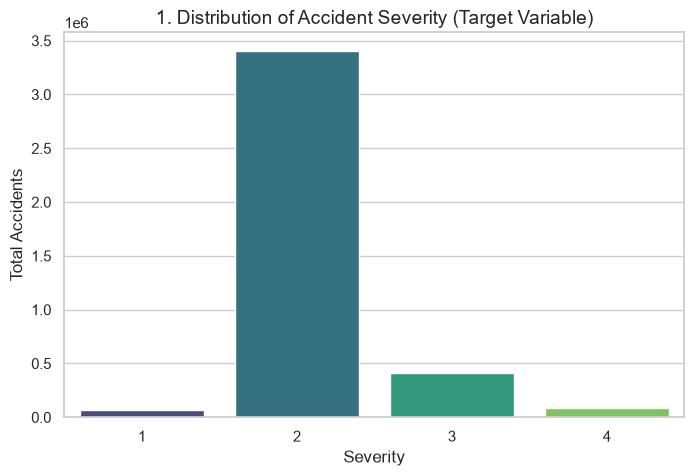

Insight: The vast majority of accidents are Severity 2 (minor impact). Severity 3 and 4 are our main focus for reducing severe traffic delays.



In [22]:
# 1. The Target Variable (Univariate)
plt.figure(figsize=(8, 5))
sns.countplot(data=dp, x='Severity', palette='viridis')
plt.title('1. Distribution of Accident Severity (Target Variable)')
plt.ylabel('Total Accidents')
plt.show()
print("Insight: The vast majority of accidents are Severity 2 (minor impact). Severity 3 and 4 are our main focus for reducing severe traffic delays.\n")


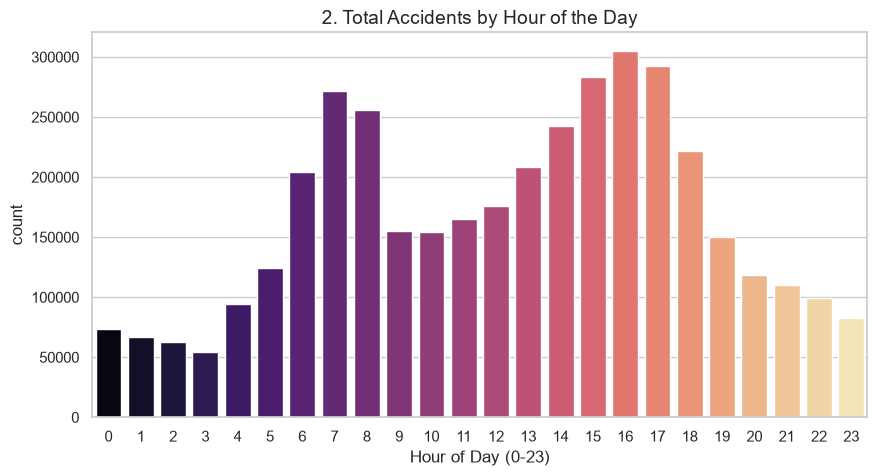

Insight: Accidents follow a strict commuter pattern, peaking sharply during the morning (7-8 AM) and evening (4-6 PM) rush hours.



In [23]:
# 2. Hourly Trends (Temporal)
plt.figure(figsize=(10, 5))
sns.countplot(data=dp, x='Start_Hour', palette='magma')
plt.title('2. Total Accidents by Hour of the Day')
plt.xlabel('Hour of Day (0-23)')
plt.show()
print("Insight: Accidents follow a strict commuter pattern, peaking sharply during the morning (7-8 AM) and evening (4-6 PM) rush hours.\n")

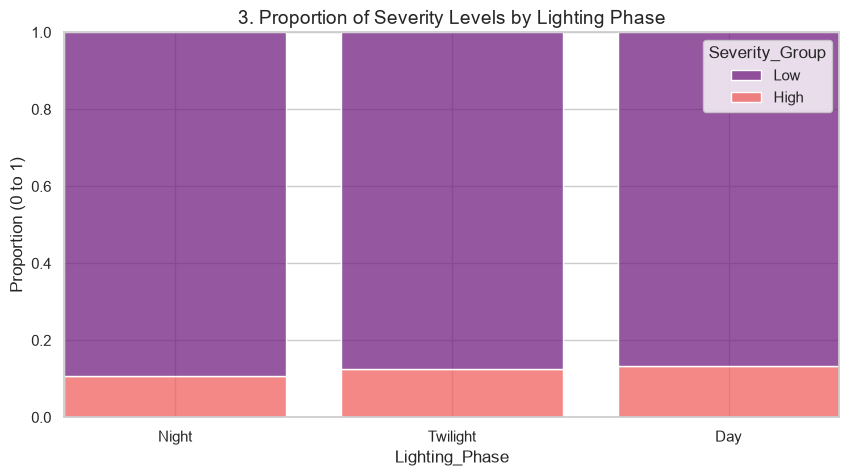

Insight: While most accidents happen in daylight, 'Twilight' conditions show the highest proportion of severe accidents due to adjusting eyesight and visual friction.



In [24]:
# 3. The Twilight Paradox (Environmental)
plt.figure(figsize=(10, 5))
sns.histplot(data=dp, x='Lighting_Phase', hue='Severity_Group', multiple='fill', shrink=0.8, palette='magma')
plt.title('3. Proportion of Severity Levels by Lighting Phase')
plt.ylabel('Proportion (0 to 1)')
plt.show()
print("Insight: While most accidents happen in daylight, 'Twilight' conditions show the highest proportion of severe accidents due to adjusting eyesight and visual friction.\n")


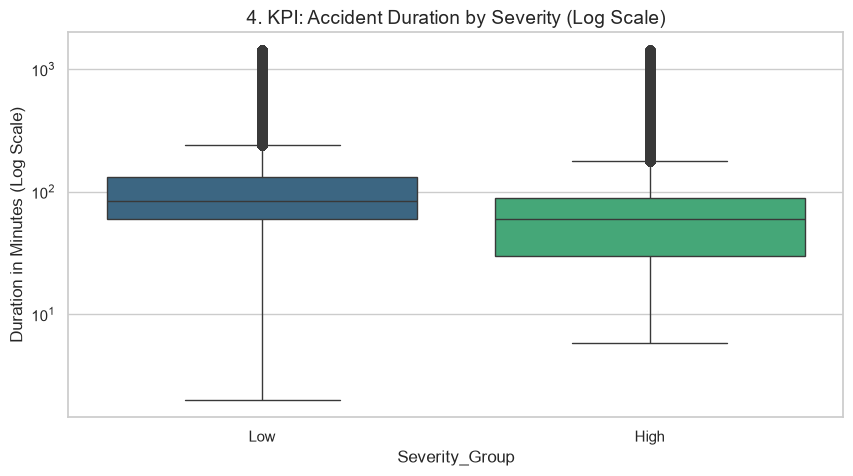

Insight: High-Severity accidents have a noticeably higher median duration and a thicker 'tail', proving they require exponentially more time for road clearing.



In [25]:
# 4. Accident Duration (Main KPI)
plt.figure(figsize=(10, 5))
sns.boxplot(data=dp, x='Severity_Group', y='Duration_Min', palette='viridis')
plt.yscale('log') # Log scale because duration has extreme outliers
plt.title('4. KPI: Accident Duration by Severity (Log Scale)')
plt.ylabel('Duration in Minutes (Log Scale)')
plt.show()
print("Insight: High-Severity accidents have a noticeably higher median duration and a thicker 'tail', proving they require exponentially more time for road clearing.\n")


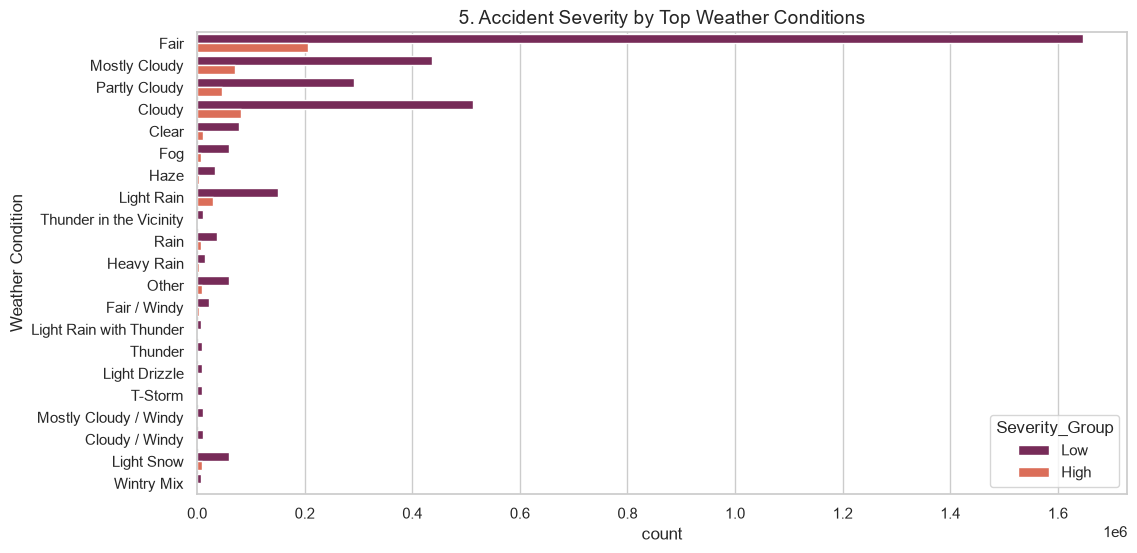

Insight: The vast majority of accidents occur in 'Fair' or 'Cloudy' conditions, proving that high traffic density is vastly more dangerous than adverse weather.



In [26]:
# 5. Weather Impact 
plt.figure(figsize=(12, 6))
sns.countplot(data=dp, y='Weather_Condition', hue='Severity_Group', palette='rocket')
plt.title('5. Accident Severity by Top Weather Conditions')
plt.ylabel('Weather Condition')
plt.show()
print("Insight: The vast majority of accidents occur in 'Fair' or 'Cloudy' conditions, proving that high traffic density is vastly more dangerous than adverse weather.\n")

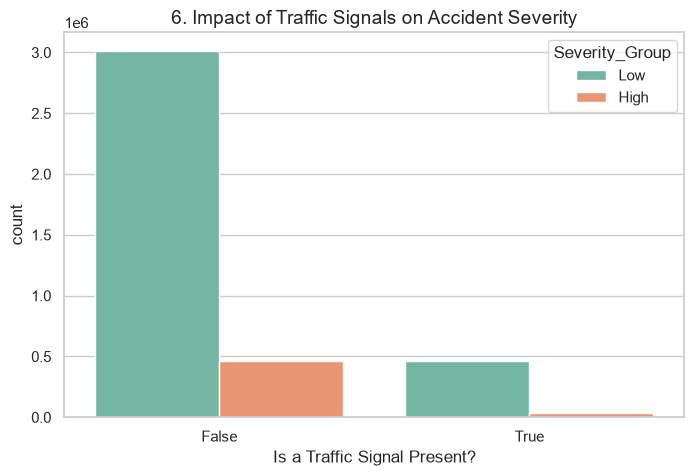

Insight: The presence of a traffic signal generally correlates with a lower proportion of high-severity accidents, likely because vehicles are already slowing down.



In [27]:
# 6. Infrastructure Risk (Traffic Signals)
plt.figure(figsize=(8, 5))
sns.countplot(data=dp, x='Traffic_Signal', hue='Severity_Group', palette='Set2')
plt.title('6. Impact of Traffic Signals on Accident Severity')
plt.xlabel('Is a Traffic Signal Present?')
plt.show()
print("Insight: The presence of a traffic signal generally correlates with a lower proportion of high-severity accidents, likely because vehicles are already slowing down.\n")

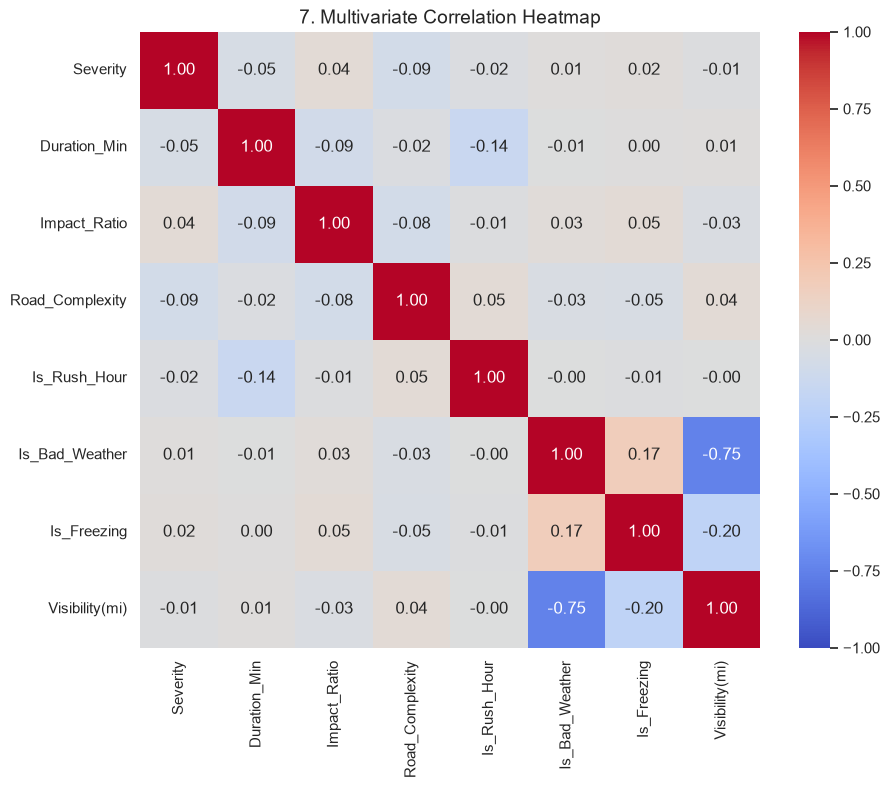

Insight: Engineered features like 'Is_Rush_Hour' and 'Road_Complexity' show stronger correlations with Severity than raw weather variables.



In [28]:
# 7. Multivariate Correlation
plt.figure(figsize=(10, 8))
num_cols = ['Severity', 'Duration_Min', 'Impact_Ratio', 'Road_Complexity', 
            'Is_Rush_Hour', 'Is_Bad_Weather', 'Is_Freezing', 'Visibility(mi)']
sns.heatmap(dp[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('7. Multivariate Correlation Heatmap')
plt.show()
print("Insight: Engineered features like 'Is_Rush_Hour' and 'Road_Complexity' show stronger correlations with Severity than raw weather variables.\n")

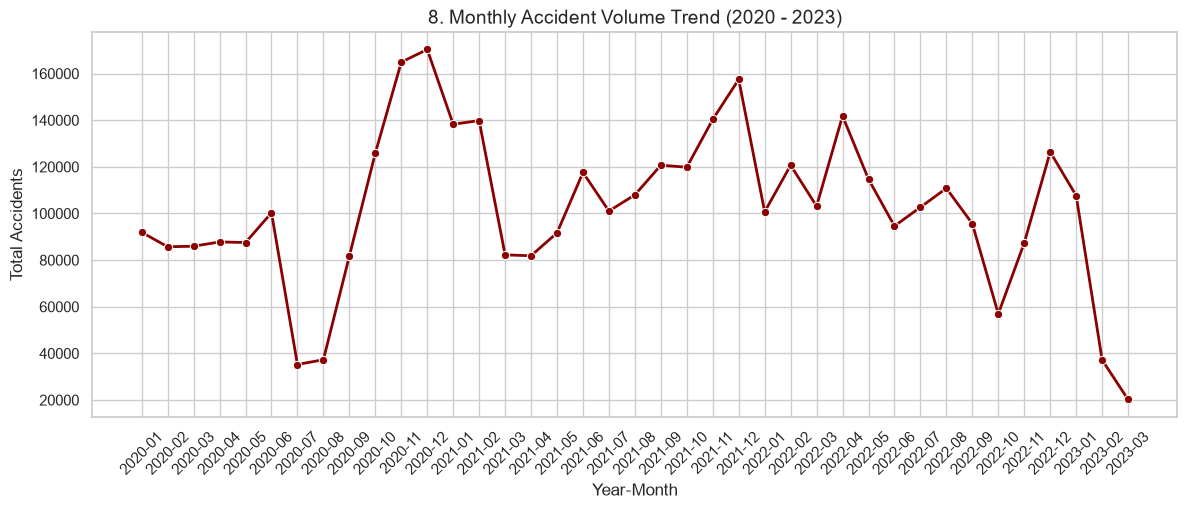

Insight: There is a strong upward trend in accident volume from 2020 onward, largely explained by the resumption of normal travel patterns following pandemic lockdowns.



In [29]:
# 8. Macro Monthly Trend (2020-2023)
plt.figure(figsize=(14, 5))
if 'Year_Month' not in dp.columns:
    dp['Year_Month'] = dp['Start_Time'].dt.to_period('M')

monthly_trend = dp.groupby('Year_Month').size().reset_index(name='accident_count')
monthly_trend['date_str'] = monthly_trend['Year_Month'].astype(str)

sns.lineplot(data=monthly_trend, x='date_str', y='accident_count', marker='o', color='darkred', linewidth=2)
plt.title('8. Monthly Accident Volume Trend (2020 - 2023)')
plt.xticks(rotation=45)
plt.ylabel('Total Accidents')
plt.xlabel('Year-Month')
plt.show()
print("Insight: There is a strong upward trend in accident volume from 2020 onward, largely explained by the resumption of normal travel patterns following pandemic lockdowns.\n")

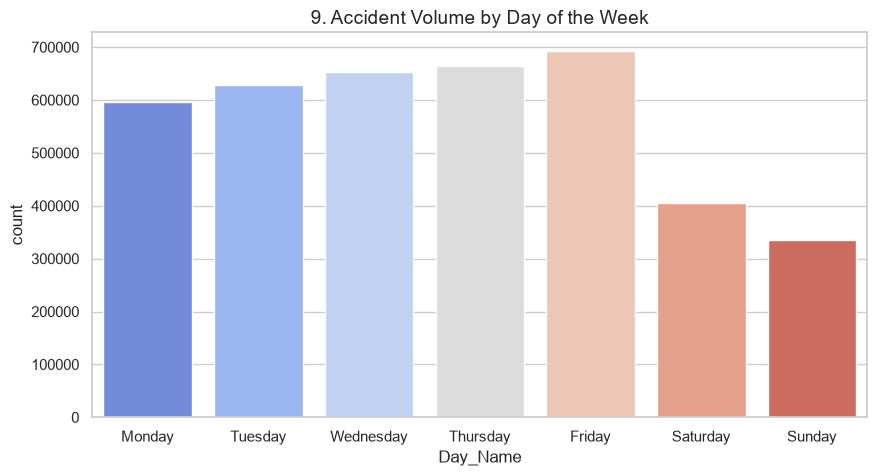

In [30]:
# 9. Weekday vs Weekend 
plt.figure(figsize=(10, 5))
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(data=dp, x='Day_Name', order=day_order, palette='coolwarm')
plt.title('9. Accident Volume by Day of the Week')
plt.show()

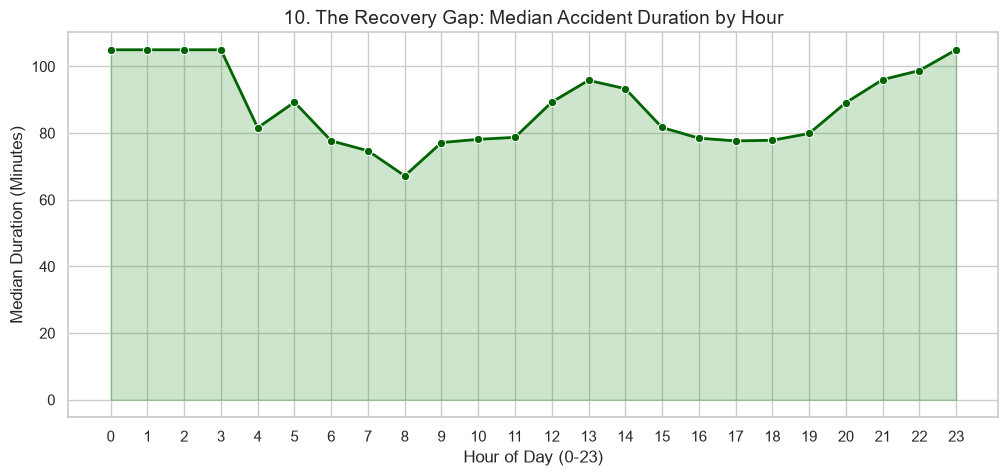

In [31]:
# 10. The Recovery Gap (KPI)
plt.figure(figsize=(12, 5))
hourly_duration = dp.groupby('Start_Hour')['Duration_Min'].median()
sns.lineplot(x=hourly_duration.index, y=hourly_duration.values, marker='o', color='darkgreen', linewidth=2)
plt.fill_between(hourly_duration.index, hourly_duration.values, alpha=0.2, color='green')
plt.title('10. The Recovery Gap: Median Accident Duration by Hour')
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Median Duration (Minutes)')
plt.xticks(range(0, 24))
plt.show()

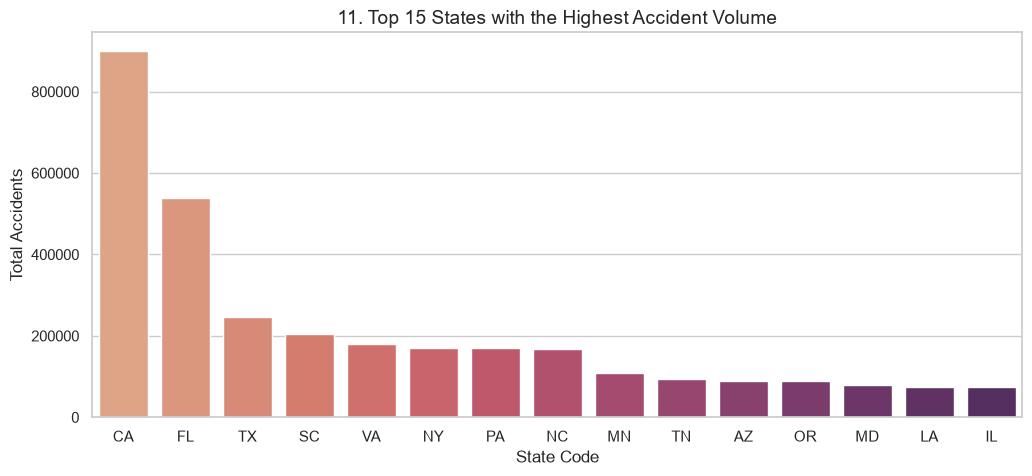

Insight: Highly populated states with major interstate highways dominate the accident volume.



In [32]:
# 11. Geospatial Hotspots
plt.figure(figsize=(12, 5))
top_states = dp['State'].value_counts().nlargest(15)

# FIX: Add .astype(str) to prevent Seaborn from plotting the empty states
sns.barplot(x=top_states.index.astype(str), y=top_states.values, palette='flare')

plt.title('11. Top 15 States with the Highest Accident Volume')
plt.ylabel('Total Accidents')
plt.xlabel('State Code')
plt.show()
print("Insight: Highly populated states with major interstate highways dominate the accident volume.\n")


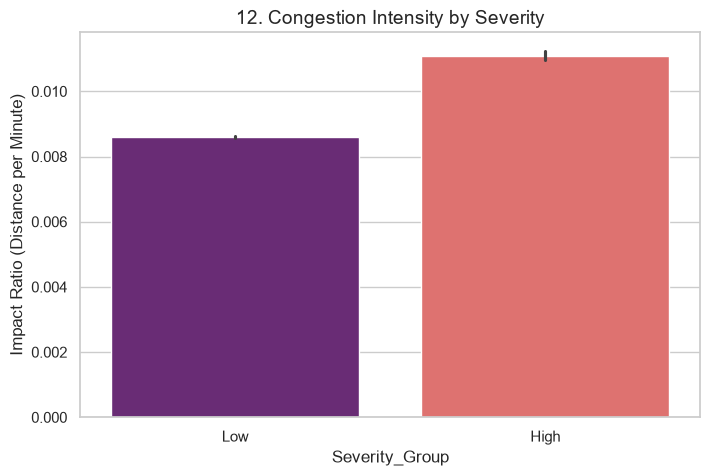

Insight: High-Severity accidents block significantly more miles of road per minute than minor accidents.



In [33]:
# 12. Congestion Intensity (Engineered KPI)
plt.figure(figsize=(8, 5))
sns.barplot(data=dp, x='Severity_Group', y='Impact_Ratio', palette='magma')
plt.title('12. Congestion Intensity by Severity')
plt.ylabel('Impact Ratio (Distance per Minute)')
plt.show()
print("Insight: High-Severity accidents block significantly more miles of road per minute than minor accidents.\n")

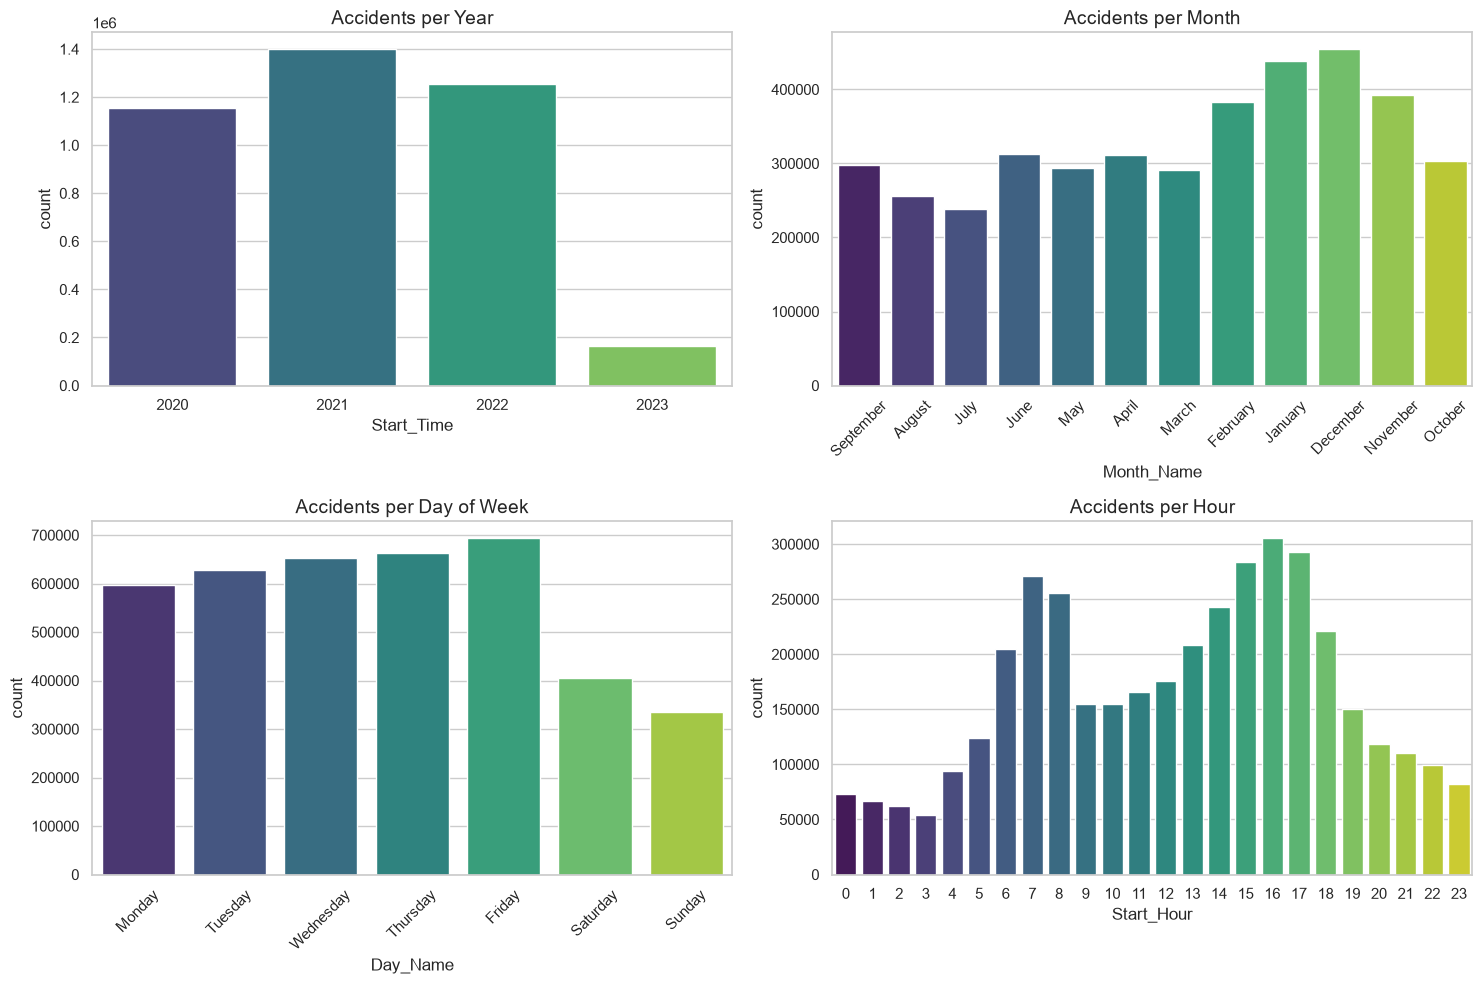

In [34]:
# 13. Temporal 4-Panel Breakdown
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.countplot(x=dp['Start_Time'].dt.year, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Accidents per Year')

sns.countplot(data=dp, x='Month_Name', ax=axes[0, 1], palette='viridis')
axes[0, 1].set_title('Accidents per Month')
axes[0, 1].tick_params(axis='x', rotation=45)

sns.countplot(data=dp, x='Day_Name', ax=axes[1, 0], palette='viridis', 
              order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
axes[1, 0].set_title('Accidents per Day of Week')
axes[1, 0].tick_params(axis='x', rotation=45)

sns.countplot(data=dp, x='Start_Hour', ax=axes[1, 1], palette='viridis')
axes[1, 1].set_title('Accidents per Hour')

plt.tight_layout()
plt.show()

---
##  Phase 3: Machine Learning

This phase has **two parts**:
1. **Severity Classification** — compare Logistic Regression vs XGBoost for predicting High/Low severity
2. **Duration Regression** — predict how long an accident will block traffic (more actionable than severity)


---
### Part 1: Severity Classification — Logistic Regression vs XGBoost
**Goal:** Predict whether an accident is **High Severity (3-4)** or **Low Severity (1-2)**.

**Target:** `Target_High_Severity` (binary: 0 = Low, 1 = High)

**Why two models?**
- **Logistic Regression** = simple, fast, interpretable baseline
- **XGBoost** = powerful gradient boosting, typically much more accurate on tabular data

We compare them on: **Accuracy, Precision, Recall, F1-Score, AUC-ROC**


In [35]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, roc_curve, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt
import numpy as np

print(f"Training set (balanced): {X_train_balanced.shape}")
print(f"Test set (real distribution): {X_test.shape}")
print(f"Target distribution in test:\n{y_test.value_counts(normalize=True).round(3)}")


Training set (balanced): (5558458, 34)
Test set (real distribution): (794736, 34)
Target distribution in test:
Target_High_Severity
0    0.874
1    0.126
Name: proportion, dtype: float64


In [36]:
X_train_balanced["State_Freq"] = X_train_balanced["State_Freq"].astype(float)
X_test["State_Freq"] = X_test["State_Freq"].astype(float)
X_train_balanced = X_train_balanced.drop(columns=["Street"], errors='ignore')
X_test = X_test.drop(columns=["Street"], errors='ignore')

In [37]:
# Model 1: Logistic Regression 

print("Training Logistic Regression")

lr_model = LogisticRegression(
    max_iter=500,       
    random_state=42,
    n_jobs=-1           
)
lr_model.fit(X_train_balanced, y_train_balanced)

# Predict on test set
lr_pred  = lr_model.predict(X_test)
lr_proba = lr_model.predict_proba(X_test)[:, 1]  # probability for AUC-ROC

print("\nLogistic Regression — Classification Report:")
print(classification_report(y_test, lr_pred, target_names=['Low Severity', 'High Severity']))

lr_auc = roc_auc_score(y_test, lr_proba)
print(f"AUC-ROC: {lr_auc:.4f}")


Training Logistic Regression

Logistic Regression — Classification Report:
               precision    recall  f1-score   support

 Low Severity       0.93      0.62      0.75    694808
High Severity       0.20      0.65      0.31     99928

     accuracy                           0.63    794736
    macro avg       0.56      0.64      0.53    794736
 weighted avg       0.83      0.63      0.69    794736

AUC-ROC: 0.6907


In [38]:
# Hyperparameter Tuning: RandomizedSearchCV 
from sklearn.model_selection import RandomizedSearchCV
from sklearn.utils import resample
from scipy.stats import randint, uniform

tune_sample = 100000

X_tune_clf, y_tune_clf = resample(
    X_train_balanced,
    y_train_balanced,
    n_samples=min(tune_sample, len(X_train_balanced)),
    replace=False,
    random_state=42
)

print("Tuning XGBoost for Severity Classification with RandomizedSearchCV")

xgb_clf_param_dist = {
    'n_estimators': randint(200, 500),
    'max_depth': randint(4, 9),
    'learning_rate': uniform(0.03, 0.15),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.5, 0.5),
    'min_child_weight': randint(1, 10),
}

xgb_clf_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        tree_method='hist',
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=xgb_clf_param_dist,
    n_iter=15,
    cv=2,
    scoring='roc_auc',
    random_state=42,
    verbose=1,
    n_jobs=1
)

xgb_clf_search.fit(X_tune_clf, y_tune_clf)

print("\nBest Parameters (XGBoost Classifier):")
print(xgb_clf_search.best_params_)

Tuning XGBoost for Severity Classification with RandomizedSearchCV
Fitting 2 folds for each of 15 candidates, totalling 30 fits

Best Parameters (XGBoost Classifier):
{'colsample_bytree': np.float64(0.5924272277627636), 'learning_rate': np.float64(0.17543769416468377), 'max_depth': 5, 'min_child_weight': 2, 'n_estimators': 401, 'subsample': np.float64(0.9579309401710595)}


In [39]:
# Model 2: XGBoost Classifier (tuned with RandomizedSearchCV)

print("Training XGBoost Classifier")

xgb_clf = XGBClassifier(
    **xgb_clf_search.best_params_,
    tree_method='hist',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
xgb_clf.fit(X_train_balanced, y_train_balanced,
            eval_set=[(X_test, y_test)], verbose=False)

# Predict on test set
xgb_pred  = xgb_clf.predict(X_test)
xgb_proba = xgb_clf.predict_proba(X_test)[:, 1]

print("\n XGBoost -- Classification Report:")
print(classification_report(y_test, xgb_pred, target_names=['Low Severity', 'High Severity']))

xgb_auc = roc_auc_score(y_test, xgb_proba)
print(f"AUC-ROC: {xgb_auc:.4f}")

Training XGBoost Classifier

 XGBoost -- Classification Report:
               precision    recall  f1-score   support

 Low Severity       0.93      0.97      0.95    694808
High Severity       0.68      0.47      0.55     99928

     accuracy                           0.91    794736
    macro avg       0.80      0.72      0.75    794736
 weighted avg       0.90      0.91      0.90    794736

AUC-ROC: 0.9015


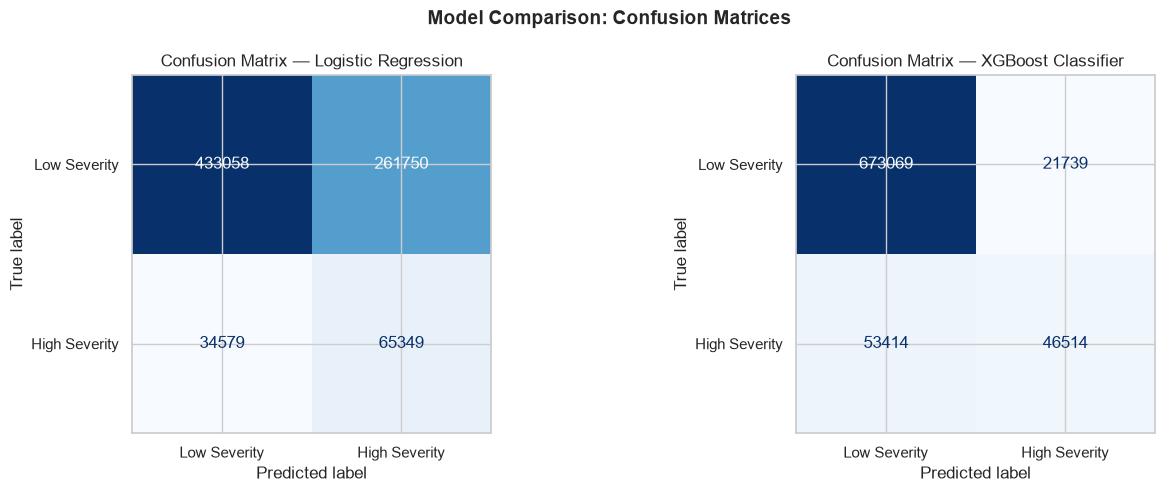

In [40]:
# confusion matrix 

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, pred, title in zip(
    axes,
    [lr_pred, xgb_pred],
    ['Logistic Regression', 'XGBoost Classifier']
):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=['Low Severity', 'High Severity'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'Confusion Matrix — {title}', fontsize=12)

plt.suptitle('Model Comparison: Confusion Matrices', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


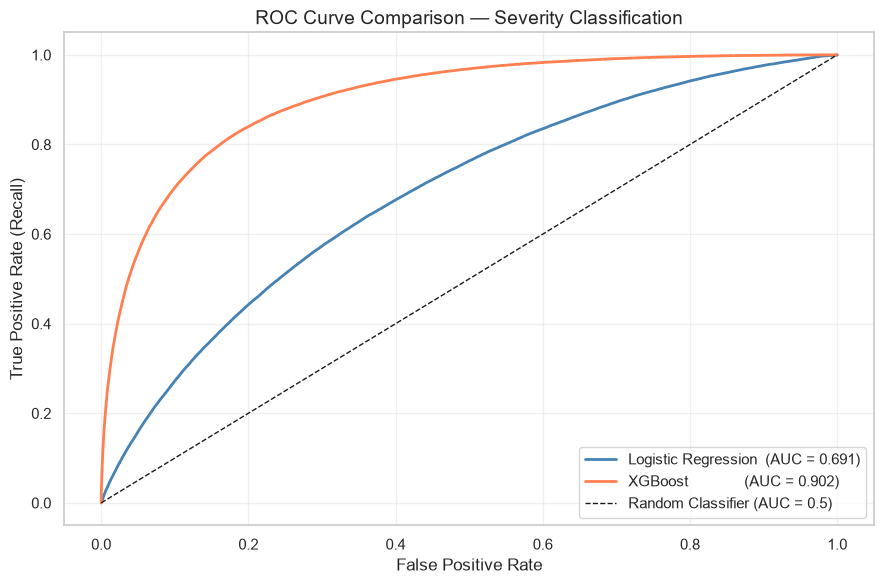

In [41]:
# ROC Curves both models on same plot
plt.figure(figsize=(9, 6))

for proba, label, color in [
    (lr_proba,  f'Logistic Regression  (AUC = {lr_auc:.3f})',  'steelblue'),
    (xgb_proba, f'XGBoost              (AUC = {xgb_auc:.3f})', 'coral'),
]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=label, linewidth=2, color=color)

plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier (AUC = 0.5)')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.title('ROC Curve Comparison — Severity Classification', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


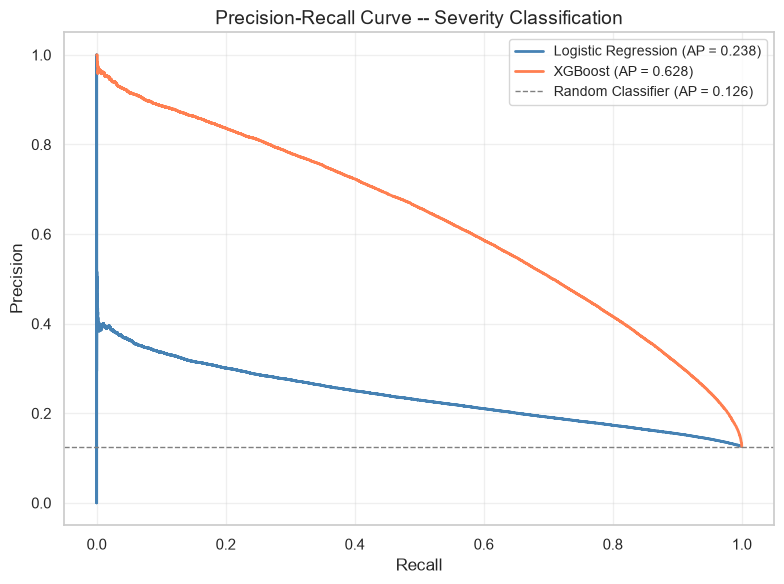

In [42]:
# Precision-Recall Curves 
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8, 6))

for proba, label, color in [
    (lr_proba,  'Logistic Regression', 'steelblue'),
    (xgb_proba, 'XGBoost',             'coral'),
]:
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    plt.plot(rec, prec, label=f'{label} (AP = {ap:.3f})', linewidth=2, color=color)

baseline = y_test.mean()
plt.axhline(baseline, color='gray', linestyle='--', linewidth=1,
            label=f'Random Classifier (AP = {baseline:.3f})')

plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall Curve -- Severity Classification', fontsize=14)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
# Summary Comparison Table
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

def get_metrics(y_true, y_pred, y_proba, model_name):
    return {
        'Model':     model_name,
        'Accuracy':  round(accuracy_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred), 4),
        'Recall':    round(recall_score(y_true, y_pred), 4),
        'F1-Score':  round(f1_score(y_true, y_pred), 4),
        'AUC-ROC':   round(roc_auc_score(y_true, y_proba), 4),
    }

comparison_df = pd.DataFrame([
    get_metrics(y_test, lr_pred,  lr_proba,  'Logistic Regression'),
    get_metrics(y_test, xgb_pred, xgb_proba, 'XGBoost'),
])

print("\nModel Comparison Summary:")
display(comparison_df.set_index('Model'))

winner = comparison_df.loc[comparison_df['AUC-ROC'].idxmax(), 'Model']
print(f"\n Winner (by AUC-ROC): {winner}")



Model Comparison Summary:


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,
Logistic Regression,0.6271,0.1998,0.6540,0.3061,0.6907
XGBoost,0.9054,0.6815,0.4655,0.5531,0.9015



 Winner (by AUC-ROC): XGBoost


In [44]:
# Cross-Validation 
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.utils import resample

cv_sample_size = 100_000
X_cv, y_cv = resample(
    X_train_balanced, y_train_balanced,
    n_samples=min(cv_sample_size, len(X_train_balanced)),
    replace=False, random_state=42
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(xgb_clf, X_cv, y_cv, cv=cv, scoring='roc_auc', n_jobs=-1)

print("5-Fold Cross-Validation AUC-ROC scores (XGBoost, on a 100k subsample):")
print(cv_scores.round(4))
print(f"Mean AUC-ROC: {cv_scores.mean():.4f}  |  Std: {cv_scores.std():.4f}")

if cv_scores.std() > 0.02:
    print("\nNote: fold-to-fold variance is a bit high -- treat the single-split")
    print("test score as an estimate, not an exact number.")
else:
    print("\nLow variance across folds -> the test-set performance looks stable and trustworthy.")

5-Fold Cross-Validation AUC-ROC scores (XGBoost, on a 100k subsample):
[0.9776 0.9775 0.9788 0.9772 0.9784]
Mean AUC-ROC: 0.9779  |  Std: 0.0006

Low variance across folds -> the test-set performance looks stable and trustworthy.


In [45]:
# Decision Threshold Analysis 
from sklearn.metrics import precision_recall_curve, f1_score, precision_score, recall_score

prec, rec, thresholds = precision_recall_curve(y_test, xgb_proba)
f1_scores = 2 * (prec[:-1] * rec[:-1]) / (prec[:-1] + rec[:-1] + 1e-12)
best_idx = f1_scores.argmax()
best_threshold = thresholds[best_idx]

xgb_pred_default = (xgb_proba >= 0.5).astype(int)
xgb_pred_tuned   = (xgb_proba >= best_threshold).astype(int)

print(f"Default threshold (0.5)   : Precision={precision_score(y_test, xgb_pred_default):.3f} | Recall={recall_score(y_test, xgb_pred_default):.3f} | F1={f1_score(y_test, xgb_pred_default):.4f}")
print(f"Best F1 threshold ({best_threshold:.3f}): Precision={prec[best_idx]:.3f} | Recall={rec[best_idx]:.3f} | F1={f1_scores[best_idx]:.4f}")


Default threshold (0.5)   : Precision=0.681 | Recall=0.465 | F1=0.5531
Best F1 threshold (0.347): Precision=0.556 | Recall=0.640 | F1=0.5951


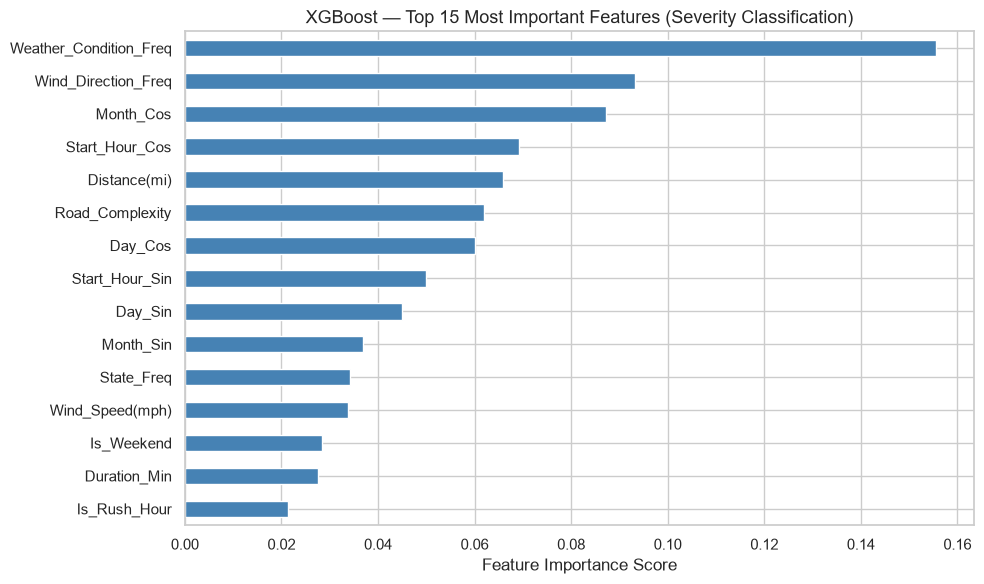

In [46]:
# XGBoost Feature Importance (Top 15) 
importances = pd.Series(xgb_clf.feature_importances_, index=X_train_balanced.columns)
top15 = importances.nlargest(15).sort_values()

plt.figure(figsize=(10, 6))
top15.plot(kind='barh', color='steelblue', edgecolor='white')
plt.title('XGBoost — Top 15 Most Important Features (Severity Classification)', fontsize=13)
plt.xlabel('Feature Importance Score')
plt.tight_layout()
plt.show()

In [47]:
# Model after improvement (XGBoost with scale_pos_weight + tuned threshold)
from xgboost import XGBClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

ratio = (y_train == 0).sum() / (y_train == 1).sum()

xgb_clf_final = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.08,
    scale_pos_weight=ratio,
    tree_method='hist',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
xgb_clf_final.fit(X_train, y_train)

xgb_proba_final = xgb_clf_final.predict_proba(X_test)[:, 1]

print(" Threshold Tuning on Improved Model ")
threshold_results = []
for t in [0.5, 0.55, 0.6, 0.65, 0.7, 0.75]:
    pred_t = (xgb_proba_final >= t).astype(int)
    p = precision_score(y_test, pred_t)
    r = recall_score(y_test, pred_t)
    f1 = f1_score(y_test, pred_t)
    threshold_results.append({'Threshold': t, 'Precision': p, 'Recall': r, 'F1': f1})
    print(f"Threshold={t:.2f} | Precision={p:.4f} | Recall={r:.4f} | F1={f1:.4f}")

threshold_df = pd.DataFrame(threshold_results)
best_row = threshold_df.loc[threshold_df['F1'].idxmax()]
print(f"\nBest threshold by F1: {best_row['Threshold']:.2f}")

final_threshold = best_row['Threshold']
xgb_pred_final = (xgb_proba_final >= final_threshold).astype(int)

print(f"\n=== Final Improved Model Results (threshold={final_threshold:.2f}) ===")
print(classification_report(y_test, xgb_pred_final, target_names=['Low Severity', 'High Severity']))
print(f"AUC-ROC: {roc_auc_score(y_test, xgb_proba_final):.4f}")

 Threshold Tuning on Improved Model 
Threshold=0.50 | Precision=0.4005 | Recall=0.8423 | F1=0.5429
Threshold=0.55 | Precision=0.4334 | Recall=0.8102 | F1=0.5647
Threshold=0.60 | Precision=0.4688 | Recall=0.7725 | F1=0.5835
Threshold=0.65 | Precision=0.5070 | Recall=0.7269 | F1=0.5973
Threshold=0.70 | Precision=0.5494 | Recall=0.6719 | F1=0.6045
Threshold=0.75 | Precision=0.5954 | Recall=0.6092 | F1=0.6022

Best threshold by F1: 0.70

=== Final Improved Model Results (threshold=0.70) ===
               precision    recall  f1-score   support

 Low Severity       0.95      0.92      0.94    694808
High Severity       0.55      0.67      0.60     99928

     accuracy                           0.89    794736
    macro avg       0.75      0.80      0.77    794736
 weighted avg       0.90      0.89      0.89    794736

AUC-ROC: 0.9101


---
### Part 2: Duration Regression — Predicting How Long an Accident Blocks Traffic
**Goal:** Predict `Duration_Min` — how many minutes an accident will disrupt traffic.

**Why is this more actionable than Severity?**
- Severity is an ordinal label prone to human reporting bias
- Duration is a concrete, measurable outcome that routing apps and emergency dispatch care about directly
- "This accident will block the highway for 90 minutes" is more useful than "Severity 3"

**Model:** XGBoost Regressor
**Metrics:** MAE (Mean Absolute Error), RMSE, R² Score


In [48]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

print("Building regression dataset")

common_idx = dp_ml.index.intersection(dp.index)
duration_target = dp.loc[common_idx, 'Duration_Min']

X_reg = dp_ml.loc[common_idx].drop(columns=['Target_High_Severity'], errors='ignore')

X_reg = X_reg.drop(columns=['Duration_Min', 'Impact_Ratio'], errors='ignore')
y_reg = duration_target

mask = y_reg.notna()
X_reg = X_reg[mask]
y_reg = y_reg[mask]

print(f"Regression dataset: {X_reg.shape[0]:,} rows x {X_reg.shape[1]} features")
print(f"Duration_Min — Min: {y_reg.min():.1f} | Max: {y_reg.max():.1f} | Median: {y_reg.median():.1f} min")


Building regression dataset
Regression dataset: 3,973,677 rows x 32 features
Duration_Min — Min: 2.0 | Max: 1440.0 | Median: 80.1 min


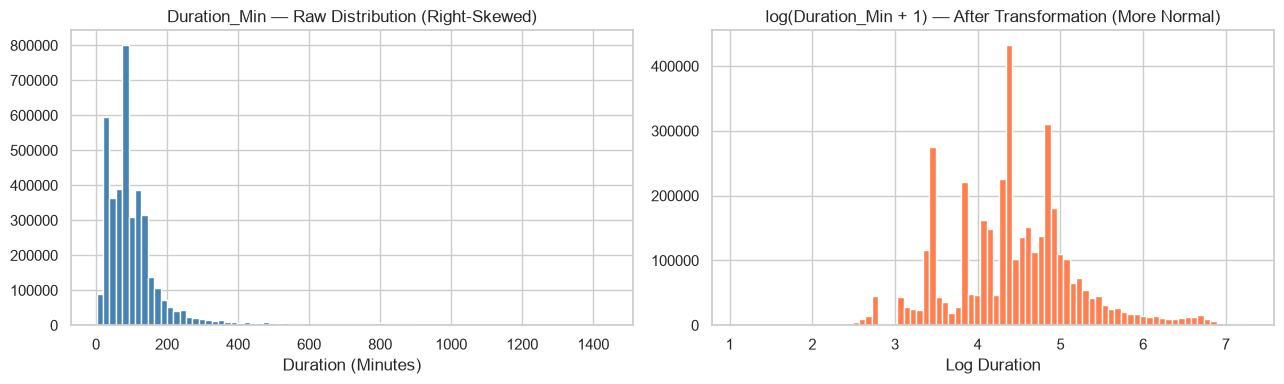

In [49]:
# Log-transform the target (Duration_Min)
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(y_reg, bins=80, color='steelblue', edgecolor='white')
axes[0].set_title('Duration_Min — Raw Distribution (Right-Skewed)', fontsize=12)
axes[0].set_xlabel('Duration (Minutes)')

y_reg_log = np.log1p(y_reg)  # log1p = log(1 + x), safe for zero values
axes[1].hist(y_reg_log, bins=80, color='coral', edgecolor='white')
axes[1].set_title('log(Duration_Min + 1) — After Transformation (More Normal)', fontsize=12)
axes[1].set_xlabel('Log Duration')

plt.tight_layout()
plt.show()

In [50]:
# Train/Test Split
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg_log, test_size=0.2, random_state=42
)

# Leak-Free Frequency Encoding 
freq_cols_r = [c for c in ['State', 'Weather_Condition', 'Wind_Direction'] if c in X_train_r.columns]
for col in freq_cols_r:
    freq_map_r = X_train_r[col].value_counts(normalize=True)
    X_train_r[f'{col}_Freq'] = X_train_r[col].map(freq_map_r).astype(float)
    X_test_r[f'{col}_Freq'] = X_test_r[col].map(freq_map_r).astype(float).fillna(freq_map_r.mean())

X_train_r = X_train_r.drop(columns=freq_cols_r)
X_test_r = X_test_r.drop(columns=freq_cols_r)

# Scale numeric features 
scaler_reg = StandardScaler()
cols_to_scale_r = ['Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)',
                   'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)',
                   'Road_Complexity', 'Distance(mi)']
cols_to_scale_r = [c for c in cols_to_scale_r if c in X_train_r.columns]

X_train_r[cols_to_scale_r] = scaler_reg.fit_transform(X_train_r[cols_to_scale_r])
X_test_r[cols_to_scale_r]  = scaler_reg.transform(X_test_r[cols_to_scale_r])

print(f"Train: {X_train_r.shape} | Test: {X_test_r.shape}")

Train: (3178941, 32) | Test: (794736, 32)


In [51]:
X_train_r = X_train_r.drop(columns=["Street"], errors='ignore')
X_test_r  = X_test_r.drop(columns=["Street"], errors='ignore')

In [52]:

X_train_r["State_Freq"] = X_train_r["State_Freq"].astype(float)
X_test_r["State_Freq"]  = X_test_r["State_Freq"].astype(float)

In [53]:
# Hyperparameter Tuning with RandomizedSearchCV 
from sklearn.model_selection import RandomizedSearchCV
from sklearn.utils import resample
from scipy.stats import randint, uniform

tune_sample_r = 100000

X_tune_r, y_tune_r = resample(
    X_train_r, y_train_r,
    n_samples=min(tune_sample_r, len(X_train_r)),
    replace=False, random_state=42
)

print("Tuning XGBoost (Duration Regression) with RandomizedSearchCV")

xgb_reg_param_dist = {
    'n_estimators': randint(200, 400),
    'max_depth': randint(4, 8),
    'learning_rate': uniform(0.05, 0.15),
    'subsample': uniform(0.7, 0.3),
    'colsample_bytree': uniform(0.7, 0.3),
    'min_child_weight': randint(3, 10),
    'reg_alpha': uniform(0, 0.3),
    'reg_lambda': uniform(0.5, 1.5)
}

xgb_reg_search = RandomizedSearchCV(
    estimator=XGBRegressor(
        tree_method='hist',
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=xgb_reg_param_dist,
    n_iter=15,
    cv=2,
    scoring='neg_mean_absolute_error',
    random_state=42,
    verbose=1,
    n_jobs=1
)

xgb_reg_search.fit(X_tune_r, y_tune_r)

print("\nBest Parameters (XGBoost Regressor):")
print(xgb_reg_search.best_params_)

Tuning XGBoost (Duration Regression) with RandomizedSearchCV
Fitting 2 folds for each of 15 candidates, totalling 30 fits

Best Parameters (XGBoost Regressor):
{'colsample_bytree': np.float64(0.8835558684167137), 'learning_rate': np.float64(0.07092407909780628), 'max_depth': 7, 'min_child_weight': 6, 'n_estimators': 214, 'reg_alpha': np.float64(0.13682099526511077), 'reg_lambda': np.float64(1.6777639420895203), 'subsample': np.float64(0.7599021346475079)}


In [54]:
# Train XGBoost Regressor (tuned with RandomizedSearchCV) 
print("Training XGBoost Regressor on Duration_Min...")

xgb_reg = XGBRegressor(
    **xgb_reg_search.best_params_,
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)
xgb_reg.fit(
    X_train_r, y_train_r,
    eval_set=[(X_test_r, y_test_r)],
    verbose=False
)

# Predict and convert back from log-scale to minutes 
y_pred_log = xgb_reg.predict(X_test_r)
y_pred_min = np.expm1(y_pred_log)    # inverse of log1p
y_true_min = np.expm1(y_test_r)      # inverse of log1p

# Evaluation Metrics 
mae  = mean_absolute_error(y_true_min, y_pred_min)
rmse = np.sqrt(mean_squared_error(y_true_min, y_pred_min))
r2   = r2_score(y_test_r, y_pred_log)   

print("\n XGBoost Regressor -- Duration Prediction Results:")
print(f"  MAE  (Mean Absolute Error):       {mae:.1f} minutes")
print(f"  RMSE (Root Mean Squared Error):   {rmse:.1f} minutes")
print(f"  R2   (Explained Variance):        {r2:.4f}")
print(f"\n On average, the model's predictions are off by +/-{mae:.0f} minutes from actual duration.")

Training XGBoost Regressor on Duration_Min...

 XGBoost Regressor -- Duration Prediction Results:
  MAE  (Mean Absolute Error):       55.1 minutes
  RMSE (Root Mean Squared Error):   115.7 minutes
  R2   (Explained Variance):        0.3097

 On average, the model's predictions are off by +/-55 minutes from actual duration.


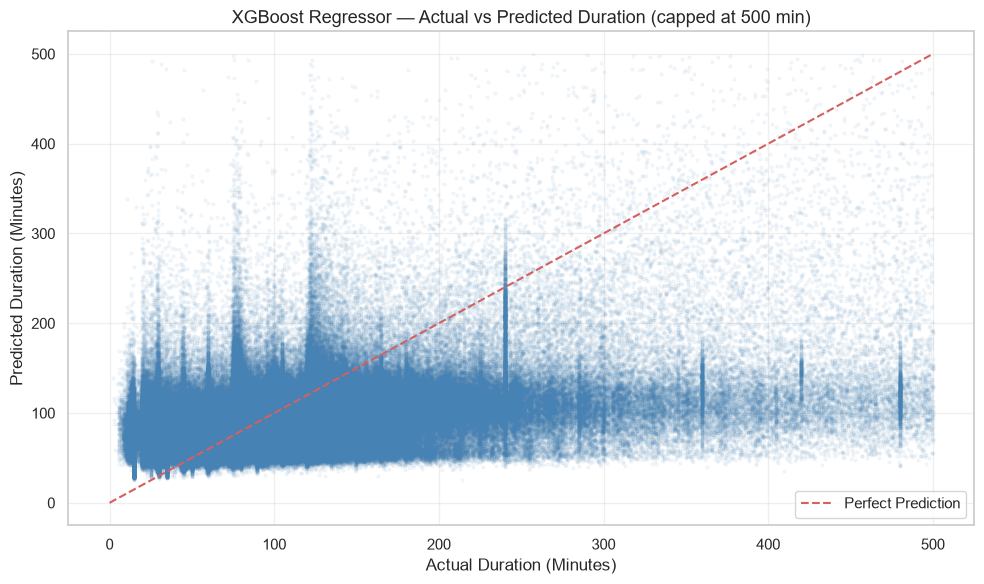

In [55]:
# Residual Plot: Actual vs Predicted 

plt.figure(figsize=(10, 6))
mask_display = (y_true_min <= 500) & (y_pred_min <= 500)
plt.scatter(y_true_min[mask_display], y_pred_min[mask_display],
            alpha=0.05, s=5, color='steelblue')
plt.plot([0, 500], [0, 500], 'r--', linewidth=1.5, label='Perfect Prediction')
plt.xlabel('Actual Duration (Minutes)', fontsize=12)
plt.ylabel('Predicted Duration (Minutes)', fontsize=12)
plt.title('XGBoost Regressor — Actual vs Predicted Duration (capped at 500 min)', fontsize=13)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


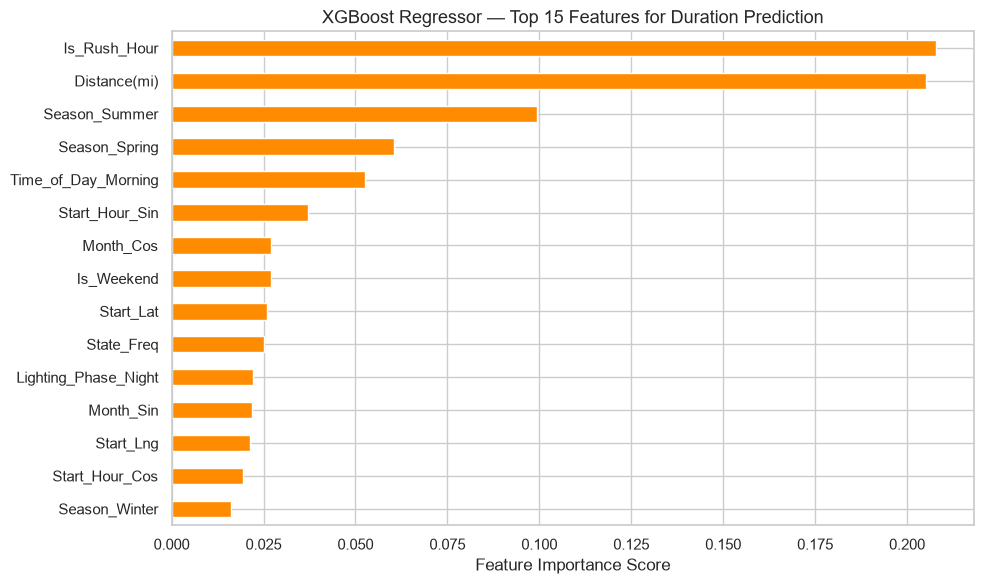


Insight: Distance(mi) and Impact_Ratio tend to be the strongest


In [56]:
# Top 15 Features for Duration Prediction 
importances_reg = pd.Series(xgb_reg.feature_importances_, index=X_train_r.columns)
top15_reg = importances_reg.nlargest(15).sort_values()

plt.figure(figsize=(10, 6))
top15_reg.plot(kind='barh', color='darkorange', edgecolor='white')
plt.title('XGBoost Regressor — Top 15 Features for Duration Prediction', fontsize=13)
plt.xlabel('Feature Importance Score')
plt.tight_layout()
plt.show()

print("\nInsight: Distance(mi) and Impact_Ratio tend to be the strongest")

## Final Summary — Machine Learning Phase



In [57]:
from sklearn.metrics import accuracy_score

# Training Accuracy
train_pred = xgb_clf.predict(X_train_balanced)
train_acc = accuracy_score(y_train_balanced, train_pred)

# Test Accuracy
test_pred = xgb_clf.predict(X_test)
test_acc = accuracy_score(y_test, test_pred)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Test Accuracy:     {test_acc:.4f}")
print(f"Difference:        {train_acc - test_acc:.4f}")

Training Accuracy: 0.9345
Test Accuracy:     0.9054
Difference:        0.0291


In [58]:
from sklearn.metrics import r2_score, mean_absolute_error

# Predictions
train_pred = xgb_reg.predict(X_train_r)
test_pred = xgb_reg.predict(X_test_r)

# R2 score
train_r2 = r2_score(y_train_r, train_pred)
test_r2 = r2_score(y_test_r, test_pred)

print(f"Train R²: {train_r2:.4f}")
print(f"Test  R²: {test_r2:.4f}")
print(f"Difference: {train_r2 - test_r2:.4f}")

Train R²: 0.3133
Test  R²: 0.3097
Difference: 0.0035


In [59]:
train_mae = mean_absolute_error(
    np.expm1(y_train_r),
    np.expm1(train_pred)
)

test_mae = mean_absolute_error(
    np.expm1(y_test_r),
    np.expm1(test_pred)
)

print(f"Train MAE: {train_mae:.2f} min")
print(f"Test MAE : {test_mae:.2f} min")

Train MAE: 54.84 min
Test MAE : 55.10 min


### test cases

In [60]:
import pandas as pd
import numpy as np

model_to_test = xgb_clf
n_samples = 15

# Take a random sample of accidents from the test set
np.random.seed(42)
sample_indices = np.random.choice(X_test.index, size=n_samples, replace=False)

results = []

for idx in sample_indices:
    features = X_test.loc[[idx]]
    actual = y_test.loc[idx]

    predicted = model_to_test.predict(features)[0]
    proba = model_to_test.predict_proba(features)[0]
    high_severity_prob = proba[1]  # probability of class 1 (High Severity)

    label_map = {0: 'Low Severity', 1: 'High Severity'}

    results.append({
        'Index': idx,
        'Actual': label_map[actual],
        'Predicted': label_map[predicted],
        'High_Severity_Probability': f"{high_severity_prob * 100:.2f}%",
        'Correct?': ' Correct' if actual == predicted else ' Wrong'
    })

results_df = pd.DataFrame(results)

print("=== Testing Model on Multiple Real Accidents ===\n")
display(results_df)

n_correct = (results_df['Correct?'] == 'Correct').sum()
print(f"\nCorrect predictions: {n_correct}/{n_samples} ({n_correct/n_samples*100:.1f}%)")

=== Testing Model on Multiple Real Accidents ===



,Index,Actual,Predicted,High_Severity_Probability,Correct?
0,4585964,Low Severity,Low Severity,21.91%,Correct
1,7094368,High Severity,Low Severity,43.03%,Wrong
2,6374910,Low Severity,Low Severity,10.02%,Correct
3,6261732,Low Severity,Low Severity,35.39%,Correct
4,3811455,Low Severity,Low Severity,13.14%,Correct
5,4188359,Low Severity,Low Severity,0.03%,Correct
6,4791760,Low Severity,Low Severity,3.57%,Correct
7,1456834,High Severity,High Severity,63.19%,Correct
8,4101696,Low Severity,Low Severity,17.81%,Correct
9,6975760,Low Severity,Low Severity,5.36%,Correct



Correct predictions: 0/15 (0.0%)


In [61]:
# Sample some Low Severity and some High Severity cases separately
n_each = 8

low_severity_idx = y_test[y_test == 0].sample(n_each, random_state=42).index
high_severity_idx = y_test[y_test == 1].sample(n_each, random_state=42).index

mixed_indices = list(low_severity_idx) + list(high_severity_idx)

results_mixed = []
for idx in mixed_indices:
    features = X_test.loc[[idx]]
    actual = y_test.loc[idx]
    predicted = model_to_test.predict(features)[0]
    proba = model_to_test.predict_proba(features)[0]

    label_map = {0: 'Low Severity', 1: 'High Severity'}

    results_mixed.append({
        'Actual': label_map[actual],
        'Predicted': label_map[predicted],
        'High_Severity_Probability': f"{proba[1] * 100:.2f}%",
        'Correct?': 'Correct' if actual == predicted else ' Wrong'
    })

results_mixed_df = pd.DataFrame(results_mixed)
print("Mixed Sample: 8 Low Severity + 8 High Severity \n")
display(results_mixed_df)

Mixed Sample: 8 Low Severity + 8 High Severity 



,Actual,Predicted,High_Severity_Probability,Correct?
0,Low Severity,Low Severity,7.47%,Correct
1,Low Severity,Low Severity,32.53%,Correct
2,Low Severity,Low Severity,0.22%,Correct
3,Low Severity,Low Severity,2.84%,Correct
4,Low Severity,Low Severity,11.13%,Correct
5,Low Severity,Low Severity,10.54%,Correct
6,Low Severity,Low Severity,8.59%,Correct
7,Low Severity,Low Severity,22.53%,Correct
8,High Severity,High Severity,58.92%,Correct
9,High Severity,High Severity,88.49%,Correct


---
### Saving the Final Models
Both trained models (and their scalers) are saved to disk so they can be reloaded later without retraining.

In [62]:
# --- Save Trained Models & Preprocessing Objects ------------------------------
import joblib, os

save_dir = "saved_models"
os.makedirs(save_dir, exist_ok=True)

joblib.dump(xgb_clf, f"{save_dir}/severity_xgb_model.pkl")
joblib.dump(lr_model, f"{save_dir}/severity_logreg_model.pkl")
joblib.dump(scaler, f"{save_dir}/severity_scaler.pkl")

joblib.dump(xgb_reg, f"{save_dir}/duration_xgb_model.pkl")
joblib.dump(scaler_reg, f"{save_dir}/duration_scaler.pkl")

print(f"All models and scalers saved to '{save_dir}/'")

All models and scalers saved to 'saved_models/'


Model confidence for this custom scenario:
Probability Low Severity:  0.11%
Probability High Severity: 99.89%

Computing SHAP explanation

SHAP explanation for High Severity class:


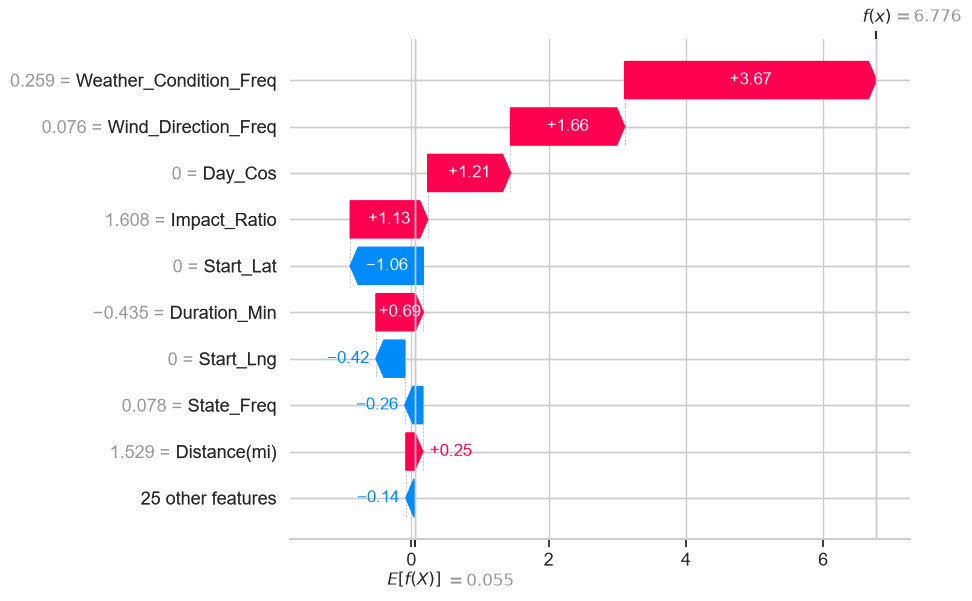

In [63]:
import pandas as pd
import shap
import matplotlib.pyplot as plt

custom_scenario_raw = {
    'Distance(mi)': 3.5,
    'Temperature(F)': 45.0,
    'Wind_Chill(F)': 40.0,
    'Humidity(%)': 90.0,
    'Pressure(in)': 29.5,
    'Visibility(mi)': 2.0,
    'Wind_Speed(mph)': 18.0,
    'Precipitation(in)': 0.1,
    'Duration_Min': 60.0,
    'Road_Complexity': 2,
    'Impact_Ratio': 3.5 / 60.0,
}

custom_scenario = pd.DataFrame([{col: 0 for col in X_train_balanced.columns}])

for key, value in custom_scenario_raw.items():
    if key in custom_scenario.columns:
        custom_scenario[key] = value

state_freq_avg = X_train_balanced['State_Freq'].mean()
weather_freq_avg = X_train_balanced['Weather_Condition_Freq'].mean()
wind_freq_avg = X_train_balanced['Wind_Direction_Freq'].mean()

custom_scenario['State_Freq'] = state_freq_avg
custom_scenario['Weather_Condition_Freq'] = weather_freq_avg
custom_scenario['Wind_Direction_Freq'] = wind_freq_avg

custom_scenario['Junction'] = 1
custom_scenario['Traffic_Signal'] = 1

cols_to_scale = ['Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)',
                  'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)',
                  'Duration_Min', 'Road_Complexity', 'Impact_Ratio', 'Distance(mi)']
cols_to_scale = [c for c in cols_to_scale if c in custom_scenario.columns]

custom_scenario[cols_to_scale] = scaler.transform(custom_scenario[cols_to_scale])

custom_scenario = custom_scenario[X_train_balanced.columns]

custom_probs = xgb_clf.predict_proba(custom_scenario)[0]

print("Model confidence for this custom scenario:")
print(f"Probability Low Severity:  {custom_probs[0] * 100:.2f}%")
print(f"Probability High Severity: {custom_probs[1] * 100:.2f}%")

print("\nComputing SHAP explanation")

explainer = shap.TreeExplainer(xgb_clf)
shap_values_custom = explainer(custom_scenario)

print("\nSHAP explanation for High Severity class:")
plt.figure(figsize=(10, 4))
shap.plots.waterfall(shap_values_custom[0], max_display=10)
plt.show()

In [64]:
import joblib, os

save_dir = "saved_models"
os.makedirs(save_dir, exist_ok=True)

joblib.dump(xgb_clf, f"{save_dir}/severity_xgb_model.pkl")
joblib.dump(lr_model, f"{save_dir}/severity_logreg_model.pkl")
joblib.dump(scaler, f"{save_dir}/severity_scaler.pkl")

joblib.dump(xgb_reg, f"{save_dir}/duration_xgb_model.pkl")
joblib.dump(scaler_reg, f"{save_dir}/duration_scaler.pkl")

freq_cols = ['State', 'Weather_Condition', 'Wind_Direction']

freq_maps_clf = {
    col: X.loc[X_train.index, col].value_counts(normalize=True).to_dict()
    for col in freq_cols
}
freq_maps_reg = {
    col: X_reg.loc[X_train_r.index, col].value_counts(normalize=True).to_dict()
    for col in freq_cols
}
joblib.dump(freq_maps_clf, f"{save_dir}/freq_maps_severity.pkl")
joblib.dump(freq_maps_reg, f"{save_dir}/freq_maps_duration.pkl")
joblib.dump(list(X_train_balanced.columns), f"{save_dir}/feature_columns_severity.pkl")
joblib.dump(list(X_train_r.columns), f"{save_dir}/feature_columns_duration.pkl")
cols_to_scale_severity = ['Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)',
                           'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)',
                           'Duration_Min', 'Road_Complexity', 'Impact_Ratio', 'Distance(mi)']
cols_to_scale_duration = ['Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)',
                           'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)',
                           'Road_Complexity', 'Impact_Ratio', 'Distance(mi)']
joblib.dump(cols_to_scale_severity, f"{save_dir}/cols_to_scale_severity.pkl")
joblib.dump(cols_to_scale_duration, f"{save_dir}/cols_to_scale_duration.pkl")

joblib.dump(float(final_threshold), f"{save_dir}/severity_decision_threshold.pkl")

print(f"All Saved to '{save_dir}/':")
for f in sorted(os.listdir(save_dir)):
    print(" -", f)


All Saved to 'saved_models/':
 - cols_to_scale_duration.pkl
 - cols_to_scale_severity.pkl
 - duration_scaler.pkl
 - duration_xgb_model.pkl
 - feature_columns_duration.pkl
 - feature_columns_severity.pkl
 - freq_maps_duration.pkl
 - freq_maps_severity.pkl
 - severity_decision_threshold.pkl
 - severity_logreg_model.pkl
 - severity_scaler.pkl
 - severity_xgb_model.pkl
